# Beta Bank - Customer Churn Prediction

**Project type:** Supervised learning · Binary classification  
**Business question:** Which customers are likely to leave the bank soon?  
**Primary metric:** F1 score (minimum required: **0.59** on the test set) · **Secondary metric:** AUC-ROC

---

## Introduction

### Business context
Beta Bank is losing customers gradually, month after month. Bank managers have established that **retaining an existing customer is cheaper than acquiring a new one**. A model that identifies customers who are likely to leave *before* they do would allow the retention team to focus its outreach (offers, calls, product reviews) on the customers where it matters most.

### Objective
Build a classification model that predicts whether a customer will leave the bank (`Exited = 1`) using historical data on customer behaviour and contract terminations. The model must:

1. reach an **F1 score of at least 0.59** on the held-out test set;
2. be evaluated with **AUC-ROC** as well, and the two metrics must be compared;
3. explicitly address the **class imbalance** present in the data, using at least two different techniques.

### Dataset
The data contains **10,000 customers** and **14 columns**.

| Column | Type | Description |
|---|---|---|
| `RowNumber` | identifier | Row index |
| `CustomerId` | identifier | Unique customer identifier |
| `Surname` | text | Customer surname |
| `CreditScore` | numeric | Credit score |
| `Geography` | categorical | Country of residence |
| `Gender` | categorical | Gender |
| `Age` | numeric | Age in years |
| `Tenure` | numeric | Years the customer's fixed-term deposit has matured |
| `Balance` | numeric | Account balance |
| `NumOfProducts` | numeric | Number of bank products used |
| `HasCrCard` | binary | Customer has a credit card (1 = yes, 0 = no) |
| `IsActiveMember` | binary | Customer is an active member (1 = yes, 0 = no) |
| `EstimatedSalary` | numeric | Estimated salary |
| **`Exited`** | **target** | **Customer has left the bank (1 = yes, 0 = no)** |

### Why F1 and AUC-ROC?
* **F1** is the harmonic mean of precision and recall. It is appropriate when the positive class (churners) is the minority, because it penalises both missed churners (low recall) and wasted retention effort on loyal customers (low precision). It depends on the **decision threshold** used to turn probabilities into yes/no predictions.
* **AUC-ROC** measures how well the model *ranks* churners above non-churners across **all** possible thresholds. It is threshold-independent, which makes it a useful complement to F1.

### Project roadmap
1. **Data loading, validation and preparation** - schema checks, missing values, exploratory analysis, feature preparation and train/validation/test split.
2. **Class balance and baseline models** - quantify the imbalance and train models that ignore it.
3. **Model improvement** - three imbalance-handling strategies (class weights, upsampling, downsampling) plus decision-threshold tuning, with hyperparameter search on the validation set.
4. **Final test** - one-time evaluation of the selected model on unseen data; F1 vs. AUC-ROC comparison.
5. **Conclusions and recommendations.**

---
# 1. Data Loading, Validation and Preparation

## 1.1 Libraries and global settings
All randomness is controlled through a single `RANDOM_STATE` so that every result in this notebook is reproducible. The F1 target from the project brief is stored as a constant and reused in every comparison.

In [41]:
import itertools
from contextlib import contextmanager
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

# Warnings stay ON for the whole notebook, so convergence, pandas-copy or any other useful message is never hidden.
# The only exception is the helper below. It silences one specific, harmless seaborn FutureWarning, and it is used
# only around the seaborn plotting calls of Section 1.6 (never around model training or evaluation).
@contextmanager
def quiet_plot_warnings():
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", category=FutureWarning, module="seaborn")
        yield


def show_md(text):
    """Render a Markdown string. The written analysis of Sections 3-5 is produced with this helper from the computed
    results, so every figure quoted in the text is read from the objects shown above it and cannot drift from them."""
    display(Markdown(text))


# Global settings
RANDOM_STATE = 12345      # reproducibility
F1_TARGET = 0.59          # minimum F1 required by the business / project brief
pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 4)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 12})

## 1.2 Loading the data
The loader checks the repository layout first (`data/Churn.csv`) and then the course-platform path (`/datasets/Churn.csv`), so the notebook runs unchanged in both environments.

In [42]:
# The loader looks for the file in the repository layout first, then in the course platform path.
CANDIDATE_PATHS = [Path("data/Churn.csv"), Path("Churn.csv"), Path("/datasets/Churn.csv")]
data_path = next((p for p in CANDIDATE_PATHS if p.exists()), None)
if data_path is None:
    raise FileNotFoundError("Churn.csv not found. Place it in ./data/ or next to this notebook.")

df = pd.read_csv(data_path)
print(f"Source file : {data_path}")
print(f"Shape       : {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Source file : data\Churn.csv
Shape       : 10,000 rows x 14 columns


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2.0,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1.0,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8.0,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1.0,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2.0,125510.82,1,1,1,79084.10,0


### Structural overview
Before any modelling, we inspect column types and non-null counts.

In [43]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           9091 non-null   float64
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(3), int64(8), str(3)
memory usage: 1.1 MB


**Findings**

* The table has **10,000 rows × 14 columns**, matching the data dictionary.
* Eight columns are integers, three are floats (`Tenure`, `Balance`, `EstimatedSalary`) and three are text (`Surname`, `Geography`, `Gender`).
* **`Tenure` is the only column with missing values** (909 missing values). Every other column is complete.
* `Tenure` is stored as a float only because of those gaps; the non-missing values are whole years.

## 1.3 Validation of variables and names
Before trusting the data, every variable is checked against the data dictionary in the project brief: column names and order, uniqueness of identifiers, valid ranges, binary encodings, and the exact set of category labels. Any failed check would need to be resolved before modelling.

In [44]:
# ---- 1) Column names vs. the data dictionary ----------------------------------------------
expected_columns = [
    "RowNumber", "CustomerId", "Surname", "CreditScore", "Geography", "Gender", "Age",
    "Tenure", "Balance", "NumOfProducts", "HasCrCard", "IsActiveMember",
    "EstimatedSalary", "Exited",
]
print("Missing columns              :", sorted(set(expected_columns) - set(df.columns)) or "none")
print("Unexpected columns           :", sorted(set(df.columns) - set(expected_columns)) or "none")
print("Column order matches brief   :", list(df.columns) == expected_columns)
print("Whitespace in column names   :", any(c != c.strip() for c in df.columns))

# ---- 2) Value-level validation -------------------------------------------------------------
text_cols = ["Surname", "Geography", "Gender"]
validation_checks = {
    "RowNumber is a unique sequence 1..N": df["RowNumber"].is_unique and df["RowNumber"].min() == 1 and df["RowNumber"].max() == len(df),
    "CustomerId is unique (one row per customer)": df["CustomerId"].is_unique,
    "No fully duplicated rows": not df.duplicated().any(),
    "CreditScore within 300-850": df["CreditScore"].between(300, 850).all(),
    "Age within 18-100": df["Age"].between(18, 100).all(),
    "Tenure within 0-10 years (non-null values)": df["Tenure"].dropna().between(0, 10).all(),
    "Tenure holds whole years (non-null values)": (df["Tenure"].dropna() % 1 == 0).all(),
    "Balance is non-negative": (df["Balance"] >= 0).all(),
    "EstimatedSalary is positive": (df["EstimatedSalary"] > 0).all(),
    "NumOfProducts within 1-4": df["NumOfProducts"].between(1, 4).all(),
    "HasCrCard is binary (0/1)": set(df["HasCrCard"].unique()) <= {0, 1},
    "IsActiveMember is binary (0/1)": set(df["IsActiveMember"].unique()) <= {0, 1},
    "Exited (target) is binary (0/1)": set(df["Exited"].unique()) <= {0, 1},
    "Geography has the expected 3 labels": set(df["Geography"].unique()) == {"France", "Germany", "Spain"},
    "Gender has the expected 2 labels": set(df["Gender"].unique()) == {"Female", "Male"},
    "Text columns have no stray whitespace": all((df[c] == df[c].str.strip()).all() for c in text_cols),
}
validation_report = pd.DataFrame(
    {"Check": list(validation_checks), "Passed": ["PASS" if bool(v) else "FAIL" for v in validation_checks.values()]}
)
n_failed = int((validation_report["Passed"] == "FAIL").sum())
print(f"\n{len(validation_report) - n_failed} of {len(validation_report)} validation checks passed")
validation_report

Missing columns              : none
Unexpected columns           : none
Column order matches brief   : True
Whitespace in column names   : False

16 of 16 validation checks passed


,Check,Passed
0,RowNumber is a unique sequence 1..N,PASS
1,CustomerId is unique (one row per customer),PASS
2,No fully duplicated rows,PASS
3,CreditScore within 300-850,PASS
4,Age within 18-100,PASS
5,Tenure within 0-10 years (non-null values),PASS
6,Tenure holds whole years (non-null values),PASS
7,Balance is non-negative,PASS
8,EstimatedSalary is positive,PASS
9,NumOfProducts within 1-4,PASS


**Findings**

* All column names match the dictionary exactly, in the expected order, with no stray whitespace.
* **16 of 16 checks passed.** `RowNumber` and `CustomerId` are unique, there are no duplicate rows, and every numeric variable sits inside a plausible range (e.g. credit scores between 350 and 850, ages between 18 and 92).
* The three binary variables (`HasCrCard`, `IsActiveMember`, `Exited`) contain only 0/1 values, and the categorical variables contain exactly the expected labels (3 countries, 2 genders) without inconsistent spelling or casing.

No corrections are required beyond the missing `Tenure` values handled next.

## 1.4 Missing values
`Tenure` has missing values. Before choosing a treatment we need to know whether the missingness is **random** or whether it carries information (for example, whether customers with missing `Tenure` churn more often).

,Missing values,Share of rows (%)
Tenure,909,9.09


,Exited,Age,CreditScore,Balance,EstimatedSalary,NumOfProducts,IsActiveMember
Tenure is missing,,,,,,,
False,0.2039,38.9492,650.7366,76522.7400,100181.2149,1.5302,0.5156
True,0.2013,38.6480,648.4510,76117.3415,99180.3894,1.5303,0.5105


Distribution of the non-missing Tenure values:
count    9091.00
mean        5.00
std         2.89
min         0.00
25%         2.00
50%         5.00
75%         7.00
max        10.00

Observed Tenure range: 0 to 10 years


,Customers,Share of non-missing values (%)
Tenure,,
0,382,4.2020
1,952,10.4719
2,950,10.4499
3,928,10.2079
4,885,9.7349
5,927,10.1969
6,881,9.6909
7,925,10.1749
8,933,10.2629


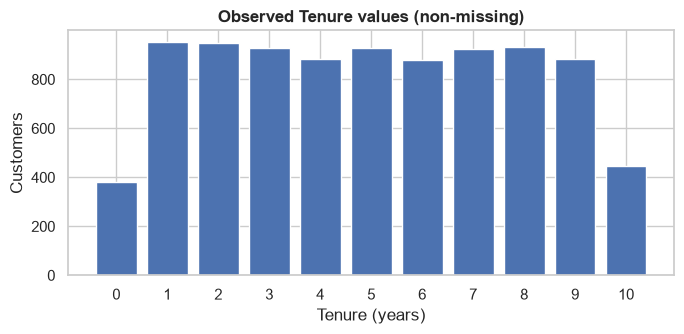

In [45]:
missing_report = pd.DataFrame({
    "Missing values": df.isna().sum(),
    "Share of rows (%)": df.isna().mean() * 100,
})
display(missing_report[missing_report["Missing values"] > 0])

# Is the missingness related to the target or to other customer attributes?
tenure_missing = df["Tenure"].isna().rename("Tenure is missing")
comparison_cols = ["Exited", "Age", "CreditScore", "Balance", "EstimatedSalary", "NumOfProducts", "IsActiveMember"]
display(df.groupby(tenure_missing)[comparison_cols].mean())

print("Distribution of the non-missing Tenure values:")
print(df["Tenure"].describe().round(2).to_string())
# Frequency of every observed Tenure value: used to describe the shape of the distribution
tenure_counts = df["Tenure"].value_counts().sort_index()
tenure_counts.index = tenure_counts.index.astype(int)
tenure_table = pd.DataFrame({
    "Customers": tenure_counts,
    "Share of non-missing values (%)": tenure_counts / tenure_counts.sum() * 100,
})
print(f"\nObserved Tenure range: {int(df['Tenure'].min())} to {int(df['Tenure'].max())} years")
display(tenure_table)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(tenure_counts.index, tenure_counts.values, color=sns.color_palette()[0])
ax.set_xticks(tenure_counts.index)
ax.set_xlabel("Tenure (years)"); ax.set_ylabel("Customers")
ax.set_title("Observed Tenure values (non-missing)")
plt.tight_layout()
plt.show()


**Findings**

* **909 customers (9.1% of the data)** have no `Tenure` value.
* Customers with and without a missing `Tenure` look practically identical: churn rate 20.1% vs. 20.4%, and the averages of age, credit score, balance, salary, number of products and activity are all within a very small margin. The gaps therefore look **random and uninformative**.
* The observed `Tenure` values range from **0 to 10 years** (mean ≈ median = 5). The frequency table and the histogram above show that each year from 1 to 9 holds a similar number of customers, while the two end values (0 and 10) are somewhat less frequent. The distribution is therefore **roughly uniform and symmetric around 5**.

**Decision.** Dropping 9% of the customers would waste data, and the absence of a pattern means a missing-value indicator would add nothing. We will **impute the median of the training set** (computed *after* the split, so no information from validation or test leaks into training). Because the distribution is roughly symmetric (mean ≈ median = 5), the median is a neutral choice that does not distort it.

## 1.5 Identifier-like columns
`RowNumber`, `CustomerId` and `Surname` are not behavioural features. We check how many distinct values they hold before deciding whether to keep them.

In [46]:
identifier_cols = ["RowNumber", "CustomerId", "Surname"]
print("Distinct values per identifier-like column:")
print(df[identifier_cols].nunique().to_string())
print(f"\nSurname: {df['Surname'].nunique() / len(df):.0%} of rows carry a distinct surname value")

Distinct values per identifier-like column:
RowNumber     10000
CustomerId    10000
Surname        2932

Surname: 29% of rows carry a distinct surname value


**Decision: remove all three columns before modelling.**

* `RowNumber` and `CustomerId` are unique per row (10,000 distinct values). They carry no behavioural signal and would only allow a flexible model to memorise individual customers.
* `Surname` has **2,932 distinct values** across 10,000 rows. One-hot encoding it would create thousands of sparse columns and encourage overfitting. In addition, surnames can act as a proxy for ethnicity or nationality, which is undesirable in a customer-treatment model for ethical and regulatory reasons.

## 1.6 Exploratory data analysis
The goal of this section is to understand the customer base and identify which variables are associated with churn. This guides feature preparation and helps interpret the model later.

### Numeric features

In [47]:
numeric_cols = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "EstimatedSalary"]
display(df[numeric_cols].describe().T)

zero_balance_share = (df["Balance"] == 0).mean()
zero_balance_by_churn = df.groupby("Exited")["Balance"].apply(lambda s: (s == 0).mean())
print(f"Customers with a zero balance: {zero_balance_share:.1%} "
      f"(retained: {zero_balance_by_churn[0]:.1%}, churned: {zero_balance_by_churn[1]:.1%})")

,count,mean,std,min,25%,50%,75%,max
CreditScore,10000.0,650.5288,96.6533,350.00,584.00,652.000,718.0000,850.00
Age,10000.0,38.9218,10.4878,18.00,32.00,37.000,44.0000,92.00
Tenure,9091.0,4.9977,2.8947,0.00,2.00,5.000,7.0000,10.00
Balance,10000.0,76485.8893,62397.4052,0.00,0.00,97198.540,127644.2400,250898.09
NumOfProducts,10000.0,1.5302,0.5817,1.00,1.00,1.000,2.0000,4.00
EstimatedSalary,10000.0,100090.2399,57510.4928,11.58,51002.11,100193.915,149388.2475,199992.48


Customers with a zero balance: 36.2% (retained: 39.1%, churned: 24.5%)


**Findings**

* **Credit score** ranges from 350 to 850 (mean 651).
* **Age** ranges from 18 to 92 with a median of 37 and a right-skewed tail of older customers.
* **Balance** is bimodal: **36.2% of customers hold a zero balance**, while the rest are spread widely up to about 250,898. Notably, the share of zero balances is higher among retained customers (39.1%) than among churners (24.5%), so customers with money on deposit are the ones leaving.
* **Estimated salary** is spread almost uniformly between roughly 12 and 199,992.
* Most customers use one or two bank products (mean 1.53).

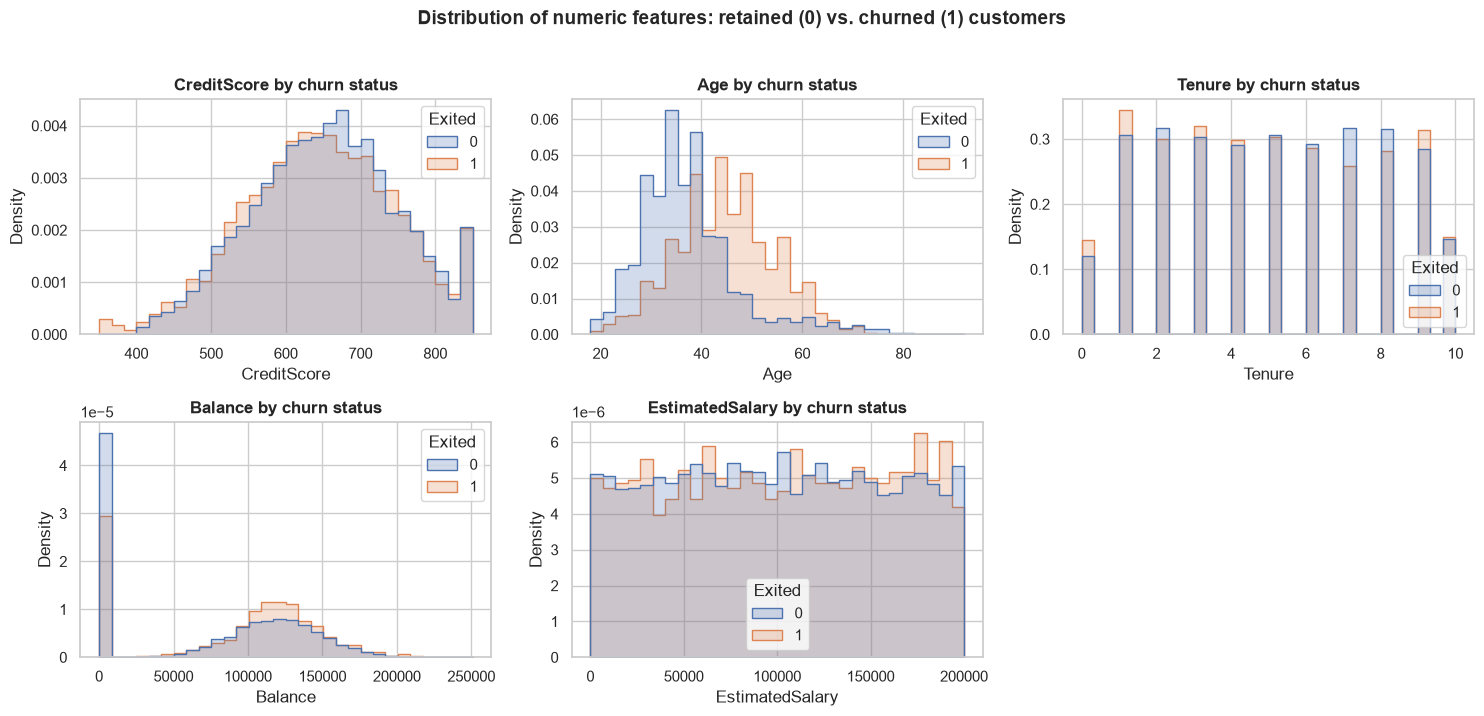

In [48]:
hist_cols = ["CreditScore", "Age", "Tenure", "Balance", "EstimatedSalary"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
with quiet_plot_warnings():
    for ax, col in zip(axes.flat, hist_cols):
        sns.histplot(data=df, x=col, hue="Exited", stat="density", common_norm=False,
                     element="step", bins=30, ax=ax)
        ax.set_title(f"{col} by churn status")
axes.flat[-1].axis("off")
fig.suptitle("Distribution of numeric features: retained (0) vs. churned (1) customers", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


**Analysis**

* **Age is the clearest separator.** The churned distribution is shifted markedly to the right: churners are concentrated in the 40–60 range, whereas retained customers peak in their 30s.
* **Balance** shows the pattern described above: churners have a much lower share of empty accounts.
* **Credit score, tenure and estimated salary** are nearly identical for both groups. They are unlikely to be strong predictors on their own.

### Churn rate across customer segments
The charts below show the percentage of customers who left within each segment. The dashed red line marks the overall churn rate.

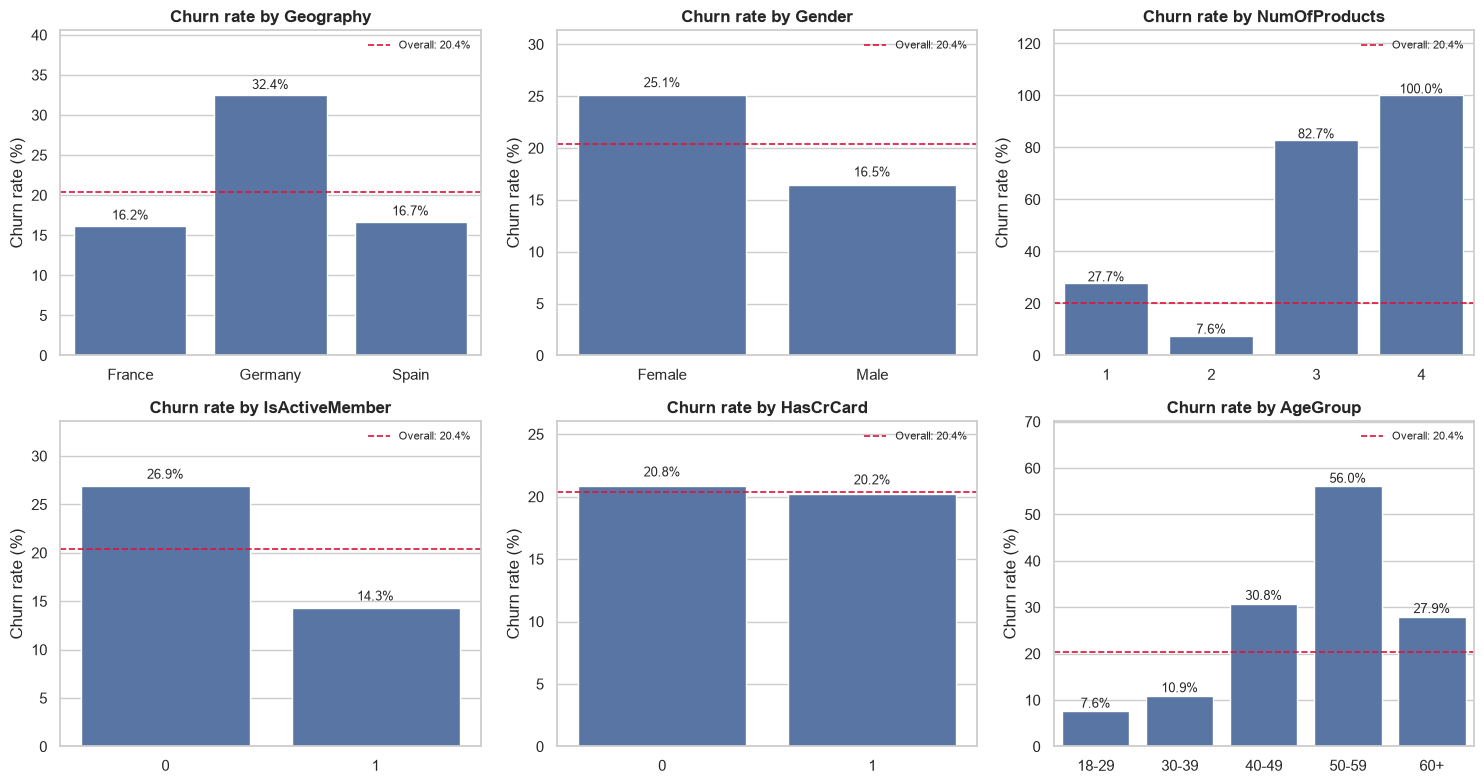

In [49]:
eda = df.copy()
eda["AgeGroup"] = pd.cut(eda["Age"], bins=[17, 29, 39, 49, 59, 100],
                         labels=["18-29", "30-39", "40-49", "50-59", "60+"])
overall_churn = eda["Exited"].mean()

rate_cols = ["Geography", "Gender", "NumOfProducts", "IsActiveMember", "HasCrCard", "AgeGroup"]
churn_rates = {c: eda.groupby(c, observed=True)["Exited"].mean() for c in rate_cols}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, rate_cols):
    rates = churn_rates[col] * 100
    with quiet_plot_warnings():
        sns.barplot(x=rates.index.astype(str), y=rates.values, ax=ax, color=sns.color_palette()[0])
    ax.axhline(overall_churn * 100, color="crimson", linestyle="--", linewidth=1.2, label=f"Overall: {overall_churn:.1%}")
    for i, v in enumerate(rates.values):
        ax.text(i, v + 0.8, f"{v:.1f}%", ha="center", fontsize=9)
    ax.set_title(f"Churn rate by {col}")
    ax.set_xlabel(""); ax.set_ylabel("Churn rate (%)")
    ax.set_ylim(0, rates.max() * 1.25)
    ax.legend(loc="upper right", fontsize=8, frameon=False)
plt.tight_layout()
plt.show()

**Analysis**

* **Geography:** customers in **Germany churn at 32.4%**, roughly double the rate in France (16.2%) and Spain (16.7%).
* **Gender:** female customers churn more often (25.1% vs. 16.5%).
* **Number of products** has a striking, non-linear relationship with churn: customers with two products are the most loyal (7.6%), those with a single product leave at 27.7%, and those with three or four products almost always leave (82.7% and 100.0%). The latter groups are small (326 customers in total), but the signal is very strong and worth investigating commercially.
* **Activity:** inactive members churn at 26.9% vs. 14.3% for active members.
* **Age group:** churn peaks among customers aged 50–59 (56.0%) and is low for those under 40 (7.6% and 10.9%).
* **Credit card ownership** has no effect (20.8% vs. 20.2%).

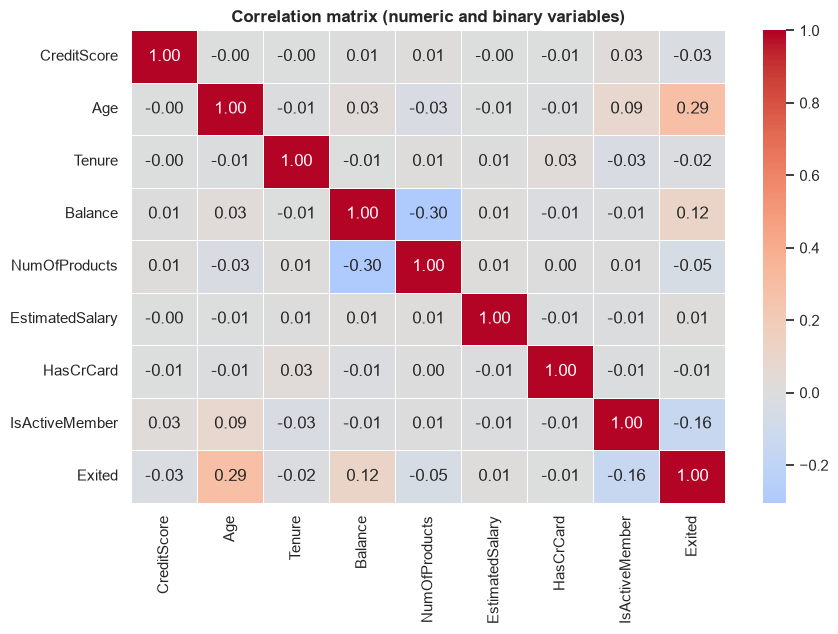

In [50]:
corr_cols = numeric_cols + ["HasCrCard", "IsActiveMember", "Exited"]
plt.figure(figsize=(9, 6.5))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation matrix (numeric and binary variables)")
plt.tight_layout()
plt.show()
corr_with_target = df[corr_cols].corr()["Exited"].drop("Exited").sort_values(key=abs, ascending=False)

**Analysis**

* Linear correlations with the target are modest. The strongest are `Age` (+0.29), `IsActiveMember` (-0.16) and `Balance` (+0.12).
* `NumOfProducts` shows a weak linear correlation (-0.05) even though it is one of the strongest drivers of churn: its effect is **U-shaped**, which a correlation coefficient cannot capture.
* The predictors are not strongly correlated with each other, so multicollinearity is not a concern.

**Implication for modelling:** because several important effects are non-linear and likely involve interactions (e.g. country × age × number of products), we expect **tree-based models to outperform a linear model**. We will test this rather than assume it.

## 1.7 Feature preparation and data split
The preparation steps below are applied in a deliberate order to **prevent data leakage**:

1. **Remove identifier columns** (`RowNumber`, `CustomerId`, `Surname`), as justified above.
2. **One-hot encode** `Geography` and `Gender`. Using `drop_first=True` removes one redundant dummy per variable, which avoids perfect collinearity (important for logistic regression).
3. **Split the data 60 / 20 / 20** into training, validation and test sets, **stratified by the target** so each subset keeps the same churn rate.
   * *Training set:* fits the models.
   * *Validation set:* compares models, hyperparameters, imbalance strategies and decision thresholds.
   * *Test set:* touched **only once**, at the very end.
4. **Impute `Tenure`** with the median of the **training** set.
5. **Standardise numeric features** with a scaler fitted on the **training** set only. Scaling is required for logistic regression to behave well and is harmless for tree-based models.

In [51]:
# 1) Remove identifier columns, which carry no predictive signal
model_df = df.drop(columns=identifier_cols)

# 2) One-hot encode the two categorical features (drop_first avoids redundant dummy columns)
model_df = pd.get_dummies(model_df, columns=["Geography", "Gender"], drop_first=True, dtype=int)

features = model_df.drop(columns="Exited")
target = model_df["Exited"]
print("Feature columns used for modelling:")
print(list(features.columns))
print(f"\nFeature matrix: {features.shape}  |  Target: {target.shape}")

Feature columns used for modelling:
['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Geography_Germany', 'Geography_Spain', 'Gender_Male']

Feature matrix: (10000, 11)  |  Target: (10000,)


Encoding turns the two categorical variables into three numeric indicator columns (`Geography_Germany`, `Geography_Spain`, `Gender_Male`); France and Female are the reference categories.

In [52]:
# 3) Split 60% train / 20% validation / 20% test, stratified to preserve the churn rate in every subset
X_train, X_temp, y_train, y_temp = train_test_split(
    features, target, test_size=0.40, stratify=target, random_state=RANDOM_STATE)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE)

split_summary = pd.DataFrame({
    "Rows": [len(y_train), len(y_valid), len(y_test)],
    "Share of data (%)": [len(y_train) / len(df) * 100, len(y_valid) / len(df) * 100, len(y_test) / len(df) * 100],
    "Churn rate (%)": [y_train.mean() * 100, y_valid.mean() * 100, y_test.mean() * 100],
}, index=["Train", "Validation", "Test"])
split_summary

,Rows,Share of data (%),Churn rate (%)
Train,6000,60.0,20.3667
Validation,2000,20.0,20.4000
Test,2000,20.0,20.3500


The three subsets contain 6,000, 2,000 and 2,000 customers respectively, and the churn rate is essentially the same in each (20.4%, 20.4% and 20.3%). Stratification worked, so validation and test results will be representative of the training distribution.

In [53]:
# Work on explicit copies: the column assignments below must not write into views of `features`.
# This avoids pandas' SettingWithCopyWarning (which the global warnings filter would otherwise hide).
X_train, X_valid, X_test = X_train.copy(), X_valid.copy(), X_test.copy()

# 4) Impute missing Tenure using the TRAIN median only (prevents information leakage)
tenure_median = X_train["Tenure"].median()
for subset in (X_train, X_valid, X_test):
    subset["Tenure"] = subset["Tenure"].fillna(tenure_median)

# 5) Standardise numeric features (scaler is fitted on TRAIN only)
scale_cols = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "EstimatedSalary"]
scaler = StandardScaler().fit(X_train[scale_cols])
for subset in (X_train, X_valid, X_test):
    subset[scale_cols] = scaler.transform(subset[scale_cols])

# Final integrity checks before modelling
assert not X_train.isna().any().any() and not X_valid.isna().any().any() and not X_test.isna().any().any()
assert list(X_train.columns) == list(X_valid.columns) == list(X_test.columns)
print(f"Tenure imputation value (train median): {tenure_median:.1f}")
print("No missing values remain; train / validation / test share identical columns.")
X_train[scale_cols].describe().loc[["mean", "std"]].round(3)

Tenure imputation value (train median): 5.0
No missing values remain; train / validation / test share identical columns.


,CreditScore,Age,Tenure,Balance,NumOfProducts,EstimatedSalary
mean,0.0,-0.0,0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0


The data is now fully numeric, has no missing values, and all three subsets share an identical column structure. The standardised features have mean 0 and standard deviation 1 on the training set, as expected. Preparation is complete.

---
# 2. Class Balance and Baseline Models

## 2.1 Examining the class balance
Churn prediction is a classic imbalanced problem: most customers stay. Before training anything we measure exactly how imbalanced the target is, because it determines which metrics are meaningful and which techniques are required.

,Customers (all data),Share (%),Customers (train)
Exited,,,
0 - Retained,7963,79.63,4778
1 - Churned,2037,20.37,1222


Imbalance ratio (retained : churned) = 3.91 : 1


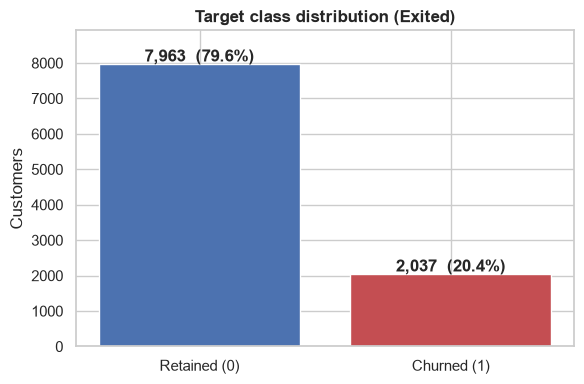

In [54]:
class_counts = y_train.value_counts().sort_index()
full_counts = target.value_counts().sort_index()
class_table = pd.DataFrame({
    "Customers (all data)": full_counts,
    "Share (%)": full_counts / len(target) * 100,
    "Customers (train)": class_counts,
}).rename(index={0: "0 - Retained", 1: "1 - Churned"})
display(class_table)

imbalance_ratio = full_counts[0] / full_counts[1]
print(f"Imbalance ratio (retained : churned) = {imbalance_ratio:.2f} : 1")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["Retained (0)", "Churned (1)"], full_counts.values, color=["#4C72B0", "#C44E52"])
for i, v in enumerate(full_counts.values):
    ax.text(i, v + 80, f"{v:,}  ({v / len(target):.1%})", ha="center", fontweight="bold")
ax.set_ylabel("Customers"); ax.set_title("Target class distribution (Exited)")
ax.set_ylim(0, full_counts.max() * 1.12)
plt.tight_layout()
plt.show()

**Findings**

* **7,963 customers (79.6%) stayed** and **2,037 (20.4%) left**, an imbalance ratio of **3.91 : 1**.
* **Accuracy is misleading here.** A "model" that predicts *every customer will stay* would be 79.6% accurate while identifying zero churners and being useless to the business. This is why the project is evaluated with **F1** and **AUC-ROC** instead.
* Left unchecked, most learning algorithms minimise overall error, which in an imbalanced dataset means **favouring the majority class**. We expect poor recall for churners.

## 2.2 Baseline: training without addressing the imbalance
To quantify the effect of the imbalance, we train three standard models on the training set **exactly as they are**: no class weights, no resampling and default hyperparameters. A majority-class dummy is included as a floor. Everything is evaluated on the **validation set** at the default 0.50 decision threshold.

| Model | Rationale |
|---|---|
| Logistic Regression | Simple, interpretable linear baseline |
| Decision Tree | Captures non-linearities and interactions; easy to explain |
| Random Forest | Ensemble of trees; usually robust on tabular data |

In [55]:
def evaluate(y_true, proba, threshold=0.5):
    """Return the metric set used throughout the project for a given decision threshold."""
    pred = (np.asarray(proba) >= threshold).astype(int)
    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "AUC-ROC": roc_auc_score(y_true, proba),
    }

In [56]:
# Models trained "as is": no class weights, no resampling, default hyperparameters
baseline_models = {
    "Majority-class dummy": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(solver="liblinear", random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE),
}

baseline_rows, baseline_valid_proba = {}, {}
for name, model in baseline_models.items():
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_valid)[:, 1]
    baseline_valid_proba[name] = proba
    baseline_rows[name] = evaluate(y_valid, proba)

baseline_results = pd.DataFrame(baseline_rows).T
baseline_results

,Accuracy,Precision,Recall,F1,AUC-ROC
Majority-class dummy,0.796,0.0000,0.0000,0.0000,0.5000
Logistic Regression,0.811,0.6087,0.2059,0.3077,0.7875
Decision Tree,0.793,0.4930,0.5147,0.5036,0.6895
Random Forest,0.870,0.7662,0.5221,0.6210,0.8624


**Findings**

* **The dummy classifier reaches 79.6% accuracy with an F1 of 0.00**, confirming that accuracy alone cannot be trusted.
* **Logistic Regression** achieves a respectable accuracy (81.1%) but an F1 of only **0.308**. Its recall is 20.6%: it **misses about four out of five churners**. Its AUC-ROC (0.788) is much healthier than its F1 suggests, which means the model ranks customers reasonably well but its 0.50 cut-off is badly suited to an imbalanced target.
* **The default Decision Tree** reaches F1 0.504 but the lowest AUC-ROC (0.690). An unconstrained tree memorises the training data (it overfits), so its probabilities are coarse.
* **The default Random Forest is the strongest baseline**: F1 0.621, AUC-ROC 0.862. Even so, its recall is only 52.2%, meaning it **still fails to flag nearly half of the churners**, while its precision (76.6%) is comparatively high. The model is conservative because the majority class dominates training.

The confusion matrices below show the same story in absolute numbers: the largest error cell for Logistic Regression and Random Forest is **churners predicted as retained** (false negatives), which is the costliest error for a retention programme.

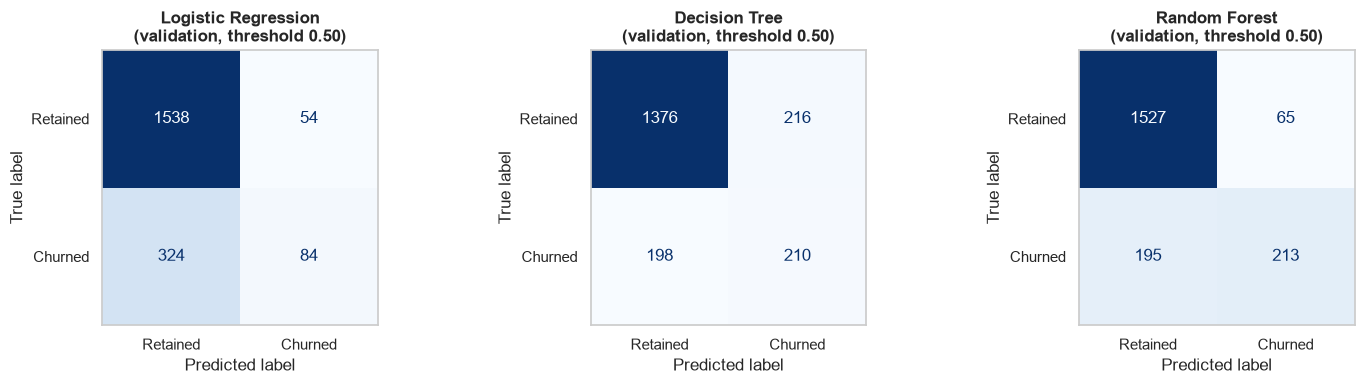

In [57]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name in zip(axes, ["Logistic Regression", "Decision Tree", "Random Forest"]):
    pred = (baseline_valid_proba[name] >= 0.5).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_valid, pred), display_labels=["Retained", "Churned"]).plot(
        ax=ax, colorbar=False, cmap="Blues", values_format="d")
    ax.set_title(f"{name}\n(validation, threshold 0.50)")
    ax.grid(False)
plt.tight_layout()
plt.show()

**Takeaway.** Ignoring the imbalance produces models that look accurate but under-detect churners. Section 3 addresses this directly.

---
# 3. Improving the Model

## 3.1 Strategy
We combine **three techniques that correct the class imbalance** with **hyperparameter tuning** and a final **decision-threshold adjustment**.

| Technique | How it works | Main trade-off |
|---|---|---|
| **Class weights** (`class_weight="balanced"`) | Errors on the minority class are penalised more heavily during training (weight ≈ n_retained / n_churned). | No change to the data; not supported by every algorithm. |
| **Upsampling** | Churner rows in the training set are repeated until both classes are roughly equal. | Duplicated rows can encourage overfitting, especially for trees. |
| **Downsampling** | A random subset of retained customers is kept so both classes are equal in size. | Discards a large share of the available information. |
| **Threshold tuning** | The probability cut-off is moved away from 0.50 to the value that maximises F1 on the validation set. | The optimum is estimated on a finite validation set. |

**Ground rules**

* Resampling is applied **only to the training set**. The validation and test sets keep the natural class distribution, so every score reflects real-world conditions.
* All models, hyperparameters and thresholds are selected using the **validation set**. The test set remains untouched until Section 4.
* The same hyperparameter grid is used for every strategy, so the strategies are compared fairly.

## 3.2 Building the balanced training sets
Resampling factors are derived from the observed imbalance rather than hard-coded.

In [58]:
def upsample(X, y, repeat):
    """Repeat the minority (churned) rows `repeat` times and shuffle."""
    X_up = pd.concat([X[y == 0]] + [X[y == 1]] * repeat)
    y_up = pd.concat([y[y == 0]] + [y[y == 1]] * repeat)
    order = np.random.RandomState(RANDOM_STATE).permutation(len(y_up))
    return X_up.iloc[order], y_up.iloc[order]


def downsample(X, y, fraction):
    """Keep every minority row and a random `fraction` of the majority rows, then shuffle."""
    X_neg = X[y == 0].sample(frac=fraction, random_state=RANDOM_STATE)
    X_down = pd.concat([X_neg, X[y == 1]])
    y_down = pd.concat([y.loc[X_neg.index], y[y == 1]])
    order = np.random.RandomState(RANDOM_STATE).permutation(len(y_down))
    return X_down.iloc[order], y_down.iloc[order]


# Resampling factors derived from the observed imbalance in the TRAIN set
n_neg, n_pos = (y_train == 0).sum(), (y_train == 1).sum()
upsample_factor = int(round(n_neg / n_pos))
downsample_fraction = n_pos / n_neg

training_sets = {
    "No balancing":  (X_train, y_train),
    "Class weights": (X_train, y_train),                                      # handled inside the model
    "Upsampling":    upsample(X_train, y_train, upsample_factor),
    "Downsampling":  downsample(X_train, y_train, downsample_fraction),
}

size_table = pd.DataFrame([
    {"Strategy": name, "Rows": len(y_), "Retained (0)": int((y_ == 0).sum()),
     "Churned (1)": int((y_ == 1).sum()), "Churn share (%)": y_.mean() * 100}
    for name, (X_, y_) in training_sets.items()
]).set_index("Strategy")
size_table

,Rows,Retained (0),Churned (1),Churn share (%)
Strategy,,,,
No balancing,6000,4778,1222,20.3667
Class weights,6000,4778,1222,20.3667
Upsampling,9666,4778,4888,50.5690
Downsampling,2444,1222,1222,50.0000


* **Upsampling** repeats each churner **4×**, producing 4,888 churners against 4,778 retained customers (churn share 50.6%).
* **Downsampling** keeps 25.6% of the retained customers, leaving a perfectly balanced but much smaller set of 2,444 rows.
* **Class weights** use the original training set; the re-weighting happens inside each model.

## 3.3 Training and tuning models on the training set, validating on the validation set
For every combination of **3 model types × 4 strategies** (no balancing, class weights, upsampling, downsampling) we search a hyperparameter grid, train each candidate on the training data and score it on the validation set. The best configuration per combination is chosen by **validation F1** (AUC-ROC breaks ties).

| Model | Hyperparameter grid |
|---|---|
| Logistic Regression | `C` ∈ {0.01, 0.1, 1, 10} |
| Decision Tree | `max_depth` ∈ 3…15 × `min_samples_leaf` ∈ {1, 5, 20} |
| Random Forest | `n_estimators` ∈ {100, 200} × `max_depth` ∈ {8, 12} × `min_samples_leaf` ∈ {3, 5} |

*Runtime note: the search evaluates 204 configurations (51 per strategy). The Random Forest grid keeps the same structure as a full grid (three hyperparameters) but uses fewer values for `n_estimators` and `max_depth`, and the models are trained on a single core without parallel jobs, so the cell finishes quickly and reliably on shared platforms. The cell prints one progress line per model/strategy combination (12 in total), followed by the total number of configurations evaluated.*


In [59]:
param_grids = {
    "Logistic Regression": {"C": [0.01, 0.1, 1, 10]},
    "Decision Tree": {"max_depth": list(range(3, 16)), "min_samples_leaf": [1, 5, 20]},
    "Random Forest": {"n_estimators": [100, 200], "max_depth": [8, 12], "min_samples_leaf": [3, 5]},
}


def expand(grid):
    keys = list(grid)
    return [dict(zip(keys, values)) for values in itertools.product(*grid.values())]


def make_model(name, params, strategy):
    class_weight = "balanced" if strategy == "Class weights" else None
    if name == "Logistic Regression":
        return LogisticRegression(solver="liblinear", class_weight=class_weight, random_state=RANDOM_STATE, **params)
    if name == "Decision Tree":
        return DecisionTreeClassifier(class_weight=class_weight, random_state=RANDOM_STATE, **params)
    # single-core training (no n_jobs): slower per fit than a parallel run, but it never stalls on shared platforms
    return RandomForestClassifier(class_weight=class_weight, random_state=RANDOM_STATE, **params)


trial_rows, best_models, best_valid_proba = [], {}, {}
n_expected = len(training_sets) * len(param_grids)
start = time.time()
for strategy, (X_fit, y_fit) in training_sets.items():
    for name, grid in param_grids.items():
        best = None
        for params in expand(grid):
            model = make_model(name, params, strategy).fit(X_fit, y_fit)
            proba = model.predict_proba(X_valid)[:, 1]
            scores = evaluate(y_valid, proba)
            trial_rows.append({"Strategy": strategy, "Model": name, "Params": params, **scores})
            if best is None or (scores["F1"], scores["AUC-ROC"]) > (best["scores"]["F1"], best["scores"]["AUC-ROC"]):
                best = {"model": model, "params": params, "scores": scores, "proba": proba}
        best_models[(name, strategy)] = best
        best_valid_proba[(name, strategy)] = best["proba"]
        print(f"[{len(best_models):>2}/{n_expected}] [{time.time() - start:5.0f} s] {strategy:<13} | {name:<19} | {len(expand(grid)):>2} configs | "
              f"best validation F1 = {best['scores']['F1']:.4f} | {best['params']}")

trials = pd.DataFrame(trial_rows)
assert len(best_models) == n_expected, f"Search incomplete: {len(best_models)} of {n_expected} combinations finished"
print(f"\n{len(trials)} hyperparameter configurations evaluated in {time.time() - start:.0f} s")
print(f"All {len(best_models)} of {n_expected} model/strategy combinations completed.")


[ 1/12] [    0 s] No balancing  | Logistic Regression |  4 configs | best validation F1 = 0.3108 | {'C': 10}
[ 2/12] [    6 s] No balancing  | Decision Tree       | 39 configs | best validation F1 = 0.5926 | {'max_depth': 7, 'min_samples_leaf': 5}
[ 3/12] [   32 s] No balancing  | Random Forest       |  8 configs | best validation F1 = 0.6049 | {'n_estimators': 100, 'max_depth': 12, 'min_samples_leaf': 3}
[ 4/12] [   32 s] Class weights | Logistic Regression |  4 configs | best validation F1 = 0.5326 | {'C': 0.1}
[ 5/12] [   37 s] Class weights | Decision Tree       | 39 configs | best validation F1 = 0.5770 | {'max_depth': 6, 'min_samples_leaf': 5}
[ 6/12] [   58 s] Class weights | Random Forest       |  8 configs | best validation F1 = 0.6466 | {'n_estimators': 200, 'max_depth': 12, 'min_samples_leaf': 3}
[ 7/12] [   59 s] Upsampling    | Logistic Regression |  4 configs | best validation F1 = 0.5324 | {'C': 0.01}
[ 8/12] [   63 s] Upsampling    | Decision Tree       | 39 configs | b

In [60]:
strategy_order = ["No balancing", "Class weights", "Upsampling", "Downsampling"]
model_order = ["Logistic Regression", "Decision Tree", "Random Forest"]

best_rows = []
for (name, strategy), best in best_models.items():
    best_rows.append({"Model": name, "Strategy": strategy, "Best hyperparameters": best["params"],
                      "F1": best["scores"]["F1"], "AUC-ROC": best["scores"]["AUC-ROC"],
                      "Precision": best["scores"]["Precision"], "Recall": best["scores"]["Recall"]})
best_table = pd.DataFrame(best_rows)

f1_pivot = best_table.pivot(index="Model", columns="Strategy", values="F1").loc[model_order, strategy_order]
auc_pivot = best_table.pivot(index="Model", columns="Strategy", values="AUC-ROC").loc[model_order, strategy_order]
print("Validation F1 (threshold 0.50) - best hyperparameters per model and strategy")
display(f1_pivot)
print("Validation AUC-ROC - same configurations")
display(auc_pivot)

print("\nBest hyperparameters found for each of the 12 model/strategy combinations (validation set, threshold 0.50)")
display(best_table.set_index(["Model", "Strategy"]).loc[[(m, st) for m in model_order for st in strategy_order]])


Validation F1 (threshold 0.50) - best hyperparameters per model and strategy


Strategy,No balancing,Class weights,Upsampling,Downsampling
Model,,,,
Logistic Regression,0.3108,0.5326,0.5324,0.5276
Decision Tree,0.5926,0.5770,0.5761,0.5974
Random Forest,0.6049,0.6466,0.6432,0.6348


Validation AUC-ROC - same configurations


Strategy,No balancing,Class weights,Upsampling,Downsampling
Model,,,,
Logistic Regression,0.7874,0.7943,0.7955,0.7934
Decision Tree,0.8314,0.8284,0.8407,0.8533
Random Forest,0.8745,0.8714,0.8702,0.8677



Best hyperparameters found for each of the 12 model/strategy combinations (validation set, threshold 0.50)


Best hyperparameters  \
Model               Strategy                                                           
Logistic Regression No balancing                                           {'C': 10}   
                    Class weights                                         {'C': 0.1}   
                    Upsampling                                           {'C': 0.01}   
                    Downsampling                                          {'C': 0.1}   
Decision Tree       No balancing             {'max_depth': 7, 'min_samples_leaf': 5}   
                    Class weights            {'max_depth': 6, 'min_samples_leaf': 5}   
                    Upsampling              {'max_depth': 7, 'min_samples_leaf': 20}   
                    Downsampling             {'max_depth': 6, 'min_samples_leaf': 1}   
Random Forest       No balancing   {'n_estimators': 100, 'max_depth': 12, 'min_sa...   
                    Class weights  {'n_estimators': 200, 'max_depth': 12, 'min_sa...   
                    Upsampling     {'n_estimators': 100, 'max_depth': 12, 'min_sa...   
                    Downsampling   {'n_estimators': 200, 'max_depth': 8, 'min_sam...   

                                       F1  AUC-ROC  Precision  Recall  
Model               Strategy                                           
Logistic Regression No balancing   0.3108   0.7874     0.6115  0.2083  
                    Class weights  0.5326   0.7943     0.4160  0.7402  
                    Upsampling     0.5324   0.7955     0.4142  0.7451  
                    Downsampling   0.5276   0.7934     0.4106  0.7377  
Decision Tree       No balancing   0.5926   0.8314     0.7075  0.5098  
                    Class weights  0.5770   0.8284     0.4623  0.7672  
                    Upsampling     0.5761   0.8407     0.4552  0.7843  
                    Downsampling   0.5974   0.8533     0.4862  0.7745  
Random Forest       No balancing   0.6049   0.8745     0.7960  0.4877  
                    Class weights  0.6466   0.8714     0.5930  0.7108  
                    Upsampling     0.6432   0.8702     0.5996  0.6936  
                    Downsampling   0.6348   0.8677     0.5276  0.7966

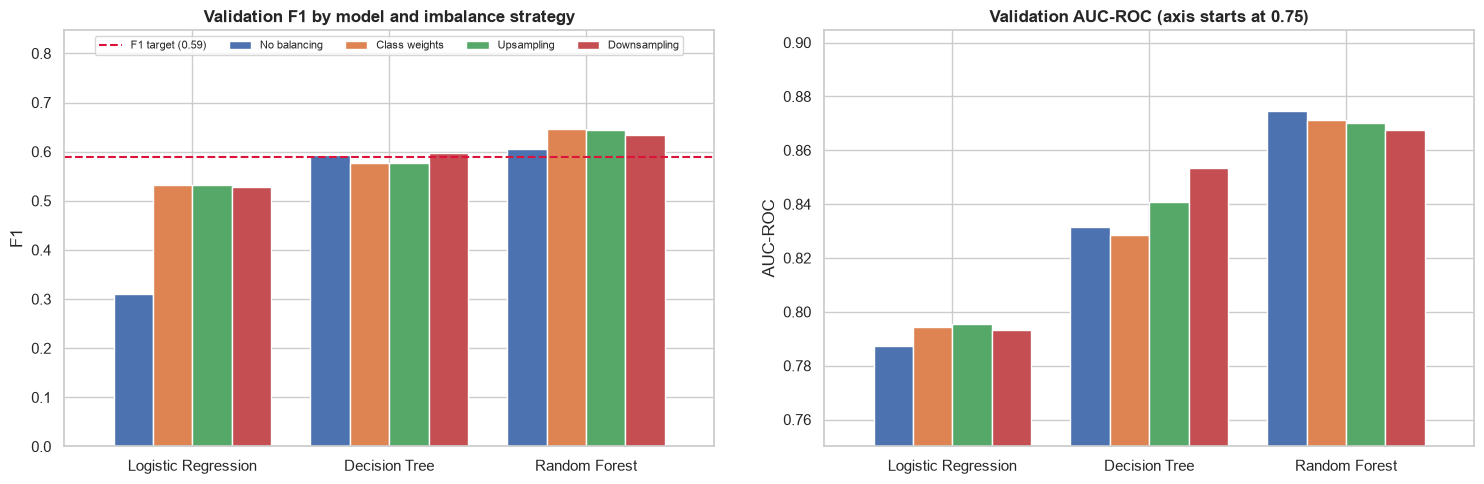

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
f1_pivot.plot(kind="bar", ax=axes[0], rot=0, width=0.8)
axes[0].axhline(F1_TARGET, color="crimson", linestyle="--", label=f"F1 target ({F1_TARGET})")
axes[0].set_title("Validation F1 by model and imbalance strategy"); axes[0].set_ylabel("F1"); axes[0].set_xlabel("")
axes[0].set_ylim(0, max(F1_TARGET, f1_pivot.values.max()) + 0.2)
axes[0].legend(fontsize=8, loc="upper center", ncol=5)

auc_floor = np.floor(auc_pivot.values.min() * 20) / 20          # axis start chosen from the data so no bar is cut off
auc_pivot.plot(kind="bar", ax=axes[1], rot=0, width=0.8, legend=False)
axes[1].set_title(f"Validation AUC-ROC (axis starts at {auc_floor:.2f})"); axes[1].set_ylabel("AUC-ROC"); axes[1].set_xlabel("")
axes[1].set_ylim(auc_floor, min(1.0, auc_pivot.values.max() + 0.03))
plt.tight_layout()
plt.show()


In [62]:
# Written analysis of Section 3.3. Every figure is read from the tables above (f1_pivot, auc_pivot).
lr, dt, rf = "Logistic Regression", "Decision Tree", "Random Forest"
balanced = ["Class weights", "Upsampling", "Downsampling"]

f1_move = f1_pivot.max(axis=1) - f1_pivot.min(axis=1)       # change in F1 across the 4 strategies, per family
auc_move = auc_pivot.max(axis=1) - auc_pivot.min(axis=1)    # change in AUC-ROC across the 4 strategies, per family
best_family = f1_pivot.idxmax()                              # best family under each strategy
rf_wins = [s for s in strategy_order if best_family[s] == rf]
family_mean = f1_pivot.mean(axis=1)
weakest, strongest = family_mean.idxmin(), family_mean.idxmax()

lr_nb = f1_pivot.loc[lr, "No balancing"]
lr_cw, lr_up, lr_down = f1_pivot.loc[lr, "Class weights"], f1_pivot.loc[lr, "Upsampling"], f1_pivot.loc[lr, "Downsampling"]
lr_bal_min, lr_bal_max = f1_pivot.loc[lr, balanced].min(), f1_pivot.loc[lr, balanced].max()
lr_auc_max = auc_pivot.loc[lr].max()

dt_min, dt_max = f1_pivot.loc[dt].min(), f1_pivot.loc[dt].max()
dt_top = f1_pivot.loc[dt].idxmax()
dt_top_f1, dt_top_auc = f1_pivot.loc[dt, dt_top], auc_pivot.loc[dt, dt_top]

rf_min, rf_max = f1_pivot.loc[rf].min(), f1_pivot.loc[rf].max()
rf_nb, rf_cw = f1_pivot.loc[rf, "No balancing"], f1_pivot.loc[rf, "Class weights"]
rf_up, rf_down = f1_pivot.loc[rf, "Upsampling"], f1_pivot.loc[rf, "Downsampling"]
rf_auc_max = auc_pivot.loc[rf].max()
rf_top, rf_low = f1_pivot.loc[rf].idxmax(), f1_pivot.loc[rf].idxmin()

if len(rf_wins) == len(strategy_order):
    rf_sentence = "Random Forest has the highest validation F1 under **every** strategy."
else:
    exceptions = ", ".join(f"{s} ({best_family[s]})" for s in strategy_order if s not in rf_wins)
    rf_sentence = (f"Random Forest has the highest validation F1 under {len(rf_wins)} of the {len(strategy_order)} strategies; "
                   f"the exceptions are {exceptions}.")

max_auc_move, max_f1_move = auc_move.max(), f1_move.max()
if max_auc_move < 0.5 * max_f1_move:
    auc_headline = "AUC-ROC moves much less than F1."
elif max_auc_move < max_f1_move:
    auc_headline = "AUC-ROC moves less than F1."
else:
    auc_headline = "AUC-ROC moves by a similar amount to F1."
auc_detail = (f"Across the four strategies, the AUC-ROC of a given family changes by at most {max_auc_move:.3f}, "
              f"whereas its F1 changes by up to {max_f1_move:.3f}.")
if max_auc_move < max_f1_move:
    auc_detail += " Balancing therefore mostly changes *where the model draws its yes/no line*, not how well it orders customers by risk."

show_md(f"""**Findings: effect of the imbalance strategies (validation set, threshold 0.50)**

* **Logistic Regression:** F1 goes from **{lr_nb:.3f}** without balancing to **{lr_bal_min:.3f}–{lr_bal_max:.3f}** with the three techniques (class weights {lr_cw:.3f}, upsampling {lr_up:.3f}, downsampling {lr_down:.3f}). Its best AUC-ROC is {lr_auc_max:.3f}.
* **Decision Tree:** F1 ranges from {dt_min:.3f} to {dt_max:.3f} across the four strategies. The best tree by F1 uses **{dt_top}** (F1 {dt_top_f1:.3f}, AUC-ROC {dt_top_auc:.3f}).
* **Random Forest:** F1 is between {rf_min:.3f} and {rf_max:.3f} (no balancing {rf_nb:.3f}, class weights {rf_cw:.3f}, upsampling {rf_up:.3f}, downsampling {rf_down:.3f}), and its AUC-ROC reaches {rf_auc_max:.3f}. The best forest by F1 uses **{rf_top}**; the lowest uses {rf_low}. {rf_sentence}
* **Across families:** averaged over the four strategies, the family with the highest F1 is **{strongest}** ({family_mean[strongest]:.3f}) and the one with the lowest is **{weakest}** ({family_mean[weakest]:.3f}).
* **{auc_headline}** {auc_detail} This is investigated further in the threshold analysis and in Section 4.
""")


**Findings: effect of the imbalance strategies (validation set, threshold 0.50)**

* **Logistic Regression:** F1 goes from **0.311** without balancing to **0.528–0.533** with the three techniques (class weights 0.533, upsampling 0.532, downsampling 0.528). Its best AUC-ROC is 0.796.
* **Decision Tree:** F1 ranges from 0.576 to 0.597 across the four strategies. The best tree by F1 uses **Downsampling** (F1 0.597, AUC-ROC 0.853).
* **Random Forest:** F1 is between 0.605 and 0.647 (no balancing 0.605, class weights 0.647, upsampling 0.643, downsampling 0.635), and its AUC-ROC reaches 0.874. The best forest by F1 uses **Class weights**; the lowest uses No balancing. Random Forest has the highest validation F1 under **every** strategy.
* **Across families:** averaged over the four strategies, the family with the highest F1 is **Random Forest** (0.632) and the one with the lowest is **Logistic Regression** (0.476).
* **AUC-ROC moves much less than F1.** Across the four strategies, the AUC-ROC of a given family changes by at most 0.025, whereas its F1 changes by up to 0.222. Balancing therefore mostly changes *where the model draws its yes/no line*, not how well it orders customers by risk. This is investigated further in the threshold analysis and in Section 4.


## 3.4 Decision-threshold tuning
Most classifiers convert a probability into a prediction using a 0.50 cut-off. When classes are imbalanced, another cut-off can produce a better trade-off between precision and recall. For each tuned model we scan thresholds from 0.10 to 0.90 and record the value that maximises validation F1. The resulting leaderboard ranks all 12 configurations.

In [63]:
THRESHOLDS = np.round(np.arange(0.10, 0.91, 0.01), 2)


def f1_curve(y_true, proba):
    return np.array([f1_score(y_true, (proba >= t).astype(int), zero_division=0) for t in THRESHOLDS])


# The F1-vs-threshold curve of each tuned configuration is computed once and reused by the table and the figure below
f1_curves = {key: f1_curve(y_valid, best["proba"]) for key, best in best_models.items()}

tuned_rows = []
for (name, strategy), best in best_models.items():
    curve = f1_curves[(name, strategy)]
    idx = int(np.argmax(curve))
    tuned_rows.append({
        "Model": name, "Strategy": strategy, "Hyperparameters": best["params"],
        "F1 @ 0.50": best["scores"]["F1"], "Best threshold": THRESHOLDS[idx],
        "F1 @ best threshold": curve[idx], "AUC-ROC": best["scores"]["AUC-ROC"],
    })
tuned = (pd.DataFrame(tuned_rows)
         .sort_values(["F1 @ best threshold", "AUC-ROC"], ascending=False)
         .reset_index(drop=True))
tuned.index += 1
tuned.index.name = "Rank"
print("Leaderboard: the 12 configurations ranked by validation F1 at their own best threshold (AUC-ROC breaks ties)")
display(tuned)


Leaderboard: the 12 configurations ranked by validation F1 at their own best threshold (AUC-ROC breaks ties)


,Model,Strategy,Hyperparameters,F1 @ 0.50,Best threshold,F1 @ best threshold,AUC-ROC
Rank,,,,,,,
1,Random Forest,No balancing,"{'n_estimators': 100, 'max_depth': 12, 'min_sa...",0.6049,0.32,0.6553,0.8745
2,Random Forest,Class weights,"{'n_estimators': 200, 'max_depth': 12, 'min_sa...",0.6466,0.52,0.6523,0.8714
3,Random Forest,Downsampling,"{'n_estimators': 200, 'max_depth': 8, 'min_sam...",0.6348,0.57,0.6498,0.8677
4,Random Forest,Upsampling,"{'n_estimators': 100, 'max_depth': 12, 'min_sa...",0.6432,0.49,0.6466,0.8702
5,Decision Tree,Downsampling,"{'max_depth': 6, 'min_samples_leaf': 1}",0.5974,0.64,0.6266,0.8533
6,Decision Tree,Class weights,"{'max_depth': 6, 'min_samples_leaf': 5}",0.5770,0.64,0.6121,0.8284
7,Decision Tree,No balancing,"{'max_depth': 7, 'min_samples_leaf': 5}",0.5926,0.31,0.6058,0.8314
8,Decision Tree,Upsampling,"{'max_depth': 7, 'min_samples_leaf': 20}",0.5761,0.64,0.6034,0.8407
9,Logistic Regression,Downsampling,{'C': 0.1},0.5276,0.53,0.5393,0.7934


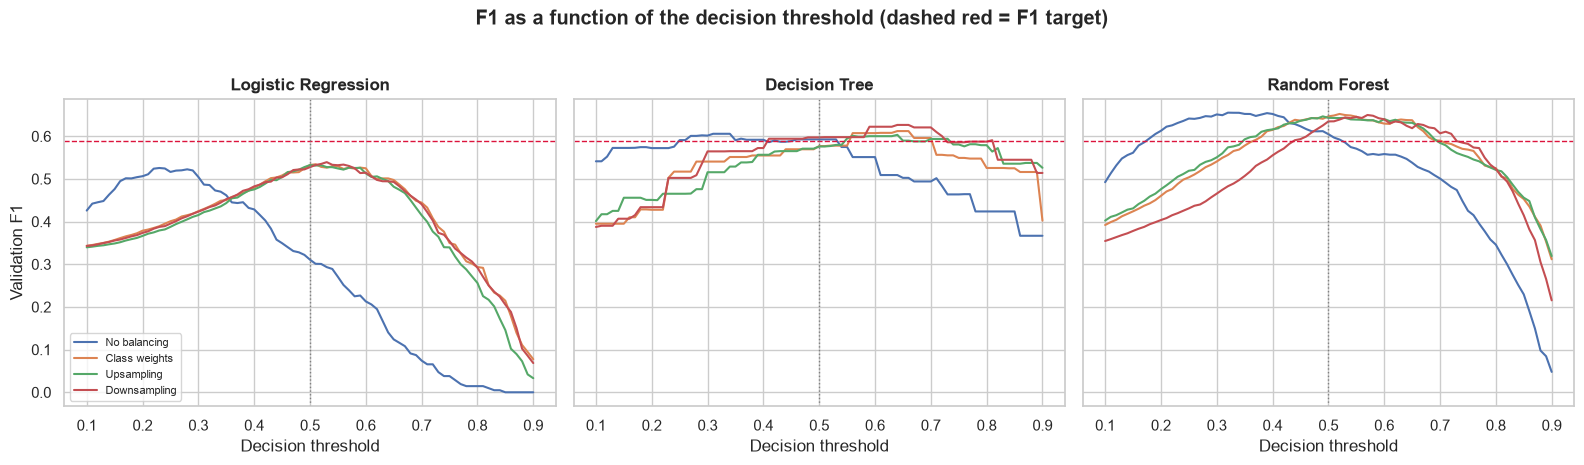

In [64]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, name in zip(axes, model_order):
    for strategy in strategy_order:
        ax.plot(THRESHOLDS, f1_curves[(name, strategy)], label=strategy)
    ax.axhline(F1_TARGET, color="crimson", linestyle="--", linewidth=1)
    ax.axvline(0.5, color="grey", linestyle=":", linewidth=1)
    ax.set_title(name); ax.set_xlabel("Decision threshold")
axes[0].set_ylabel("Validation F1"); axes[0].legend(fontsize=8)
fig.suptitle("F1 as a function of the decision threshold (dashed red = F1 target)", fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

In [65]:
# Written analysis of Section 3.4. Every figure is read from the leaderboard (tuned) displayed above.
top4 = tuned.head(4)
top4_f1 = top4["F1 @ best threshold"]
top4_min, top4_max, top4_spread = top4_f1.min(), top4_f1.max(), top4_f1.max() - top4_f1.min()
if (top4["Model"] == "Random Forest").all():
    top4_sentence = "**The top four configurations are all Random Forests**"
else:
    top4_labels = "; ".join(f"{r.Model} + {r.Strategy}" for r in top4.itertuples())
    top4_sentence = f"**The top four configurations are: {top4_labels}**"

rf_rows = tuned[tuned["Model"] == "Random Forest"].set_index("Strategy").loc[strategy_order]
rf_lines = "\n".join(
    f"  * {strat}: F1 {row['F1 @ 0.50']:.3f} at 0.50, **{row['F1 @ best threshold']:.3f}** at its best threshold **{row['Best threshold']:.2f}**"
    for strat, row in rf_rows.iterrows())
rf_tuned_spread = rf_rows["F1 @ best threshold"].max() - rf_rows["F1 @ best threshold"].min()
if rf_tuned_spread < 0.02:
    converge = (f"After threshold tuning the four forests reach similar F1 peaks (spread {rf_tuned_spread:.3f}), so balancing and threshold "
                "tuning are largely two routes to the same result: re-weighting or resampling the classes effectively moves the model's "
                "operating point, as the F1-versus-threshold curves above show.")
else:
    converge = (f"After threshold tuning the four forests still differ by {rf_tuned_spread:.3f} F1, so the choice of imbalance strategy "
                "keeps some influence beyond the decision threshold.")

gap12 = tuned.loc[1, "F1 @ best threshold"] - tuned.loc[2, "F1 @ best threshold"]
n_valid, n_valid_pos = len(y_valid), int(y_valid.sum())
if gap12 < 0.01:
    noise = (f"The gap between rank 1 and rank 2 is {gap12:.4f} F1, which is **within the noise** of a {n_valid:,}-customer validation set "
             f"with {n_valid_pos} churners. We should not over-interpret it.")
else:
    noise = (f"Rank 1 leads rank 2 by {gap12:.4f} F1. This is still estimated on a validation set of {n_valid:,} customers "
             f"({n_valid_pos} churners), so it carries sampling noise.")

lr_rows = tuned[tuned["Model"] == "Logistic Regression"].set_index("Strategy").loc[strategy_order]
lr_gain = lr_rows["F1 @ best threshold"] - lr_rows["F1 @ 0.50"]
lr_nb_from, lr_nb_to = lr_rows.loc["No balancing", "F1 @ 0.50"], lr_rows.loc["No balancing", "F1 @ best threshold"]
lr_bal_gain_min, lr_bal_gain_max = lr_gain.drop("No balancing").min(), lr_gain.drop("No balancing").max()
lr_best_tuned, rf_best_tuned = lr_rows["F1 @ best threshold"].max(), rf_rows["F1 @ best threshold"].max()

show_md(f"""**Findings**

* {top4_sentence}, and their tuned validation F1 values are between {top4_min:.3f} and {top4_max:.3f}.
* **Balancing and threshold tuning for the Random Forest** (validation F1 at the default 0.50 threshold and at each configuration's own best threshold):
{rf_lines}

  {converge}
* {noise}
* **Logistic Regression:** threshold tuning moves the unbalanced model from F1 {lr_nb_from:.3f} to {lr_nb_to:.3f}, and the balanced variants by {lr_bal_gain_min:+.3f} to {lr_bal_gain_max:+.3f}. Its best tuned F1 is {lr_best_tuned:.3f}, versus {rf_best_tuned:.3f} for the best forest.
* **Limitation of the selection procedure.** The hyperparameters of each model/strategy combination were chosen by F1 at the default 0.50 threshold, and the threshold was tuned only afterwards. A configuration that is slightly worse at 0.50 could be better at its own optimal threshold. Since the top four configurations differ by only {top4_spread:.3f} F1, the effect is expected to be small, but it was not tested here.
""")


**Findings**

* **The top four configurations are all Random Forests**, and their tuned validation F1 values are between 0.647 and 0.655.
* **Balancing and threshold tuning for the Random Forest** (validation F1 at the default 0.50 threshold and at each configuration's own best threshold):
  * No balancing: F1 0.605 at 0.50, **0.655** at its best threshold **0.32**
  * Class weights: F1 0.647 at 0.50, **0.652** at its best threshold **0.52**
  * Upsampling: F1 0.643 at 0.50, **0.647** at its best threshold **0.49**
  * Downsampling: F1 0.635 at 0.50, **0.650** at its best threshold **0.57**

  After threshold tuning the four forests reach similar F1 peaks (spread 0.009), so balancing and threshold tuning are largely two routes to the same result: re-weighting or resampling the classes effectively moves the model's operating point, as the F1-versus-threshold curves above show.
* The gap between rank 1 and rank 2 is 0.0030 F1, which is **within the noise** of a 2,000-customer validation set with 408 churners. We should not over-interpret it.
* **Logistic Regression:** threshold tuning moves the unbalanced model from F1 0.311 to 0.526, and the balanced variants by +0.000 to +0.012. Its best tuned F1 is 0.539, versus 0.655 for the best forest.
* **Limitation of the selection procedure.** The hyperparameters of each model/strategy combination were chosen by F1 at the default 0.50 threshold, and the threshold was tuned only afterwards. A configuration that is slightly worse at 0.50 could be better at its own optimal threshold. Since the top four configurations differ by only 0.009 F1, the effect is expected to be small, but it was not tested here.


## 3.5 Selecting the best model
The champion is the configuration with the **highest validation F1** after threshold tuning (the leaderboard's rank 1).

In [66]:
champion_row = tuned.iloc[0]
champion_key = (champion_row["Model"], champion_row["Strategy"])
champion = best_models[champion_key]["model"]
champion_threshold = float(champion_row["Best threshold"])

print("Selected configuration (highest validation F1):")
print(f"  Model          : {champion_row['Model']}")
print(f"  Imbalance fix  : {champion_row['Strategy']}")
print(f"  Hyperparameters: {champion_row['Hyperparameters']}")
print(f"  Threshold      : {champion_threshold:.2f}")
print(f"  Validation F1  : {champion_row['F1 @ best threshold']:.4f}   |   Validation AUC-ROC: {champion_row['AUC-ROC']:.4f}")

# Same model family without any imbalance handling, for a like-for-like reference
no_balance_same_model = tuned[(tuned["Model"] == champion_row["Model"]) & (tuned["Strategy"] == "No balancing")].iloc[0]
print(f"\nSame model without imbalance handling: F1 @ 0.50 = {no_balance_same_model['F1 @ 0.50']:.4f}, "
      f"F1 @ its best threshold = {no_balance_same_model['F1 @ best threshold']:.4f}")

# ---- Evidence that the selected configuration is the best one on the validation set ----
print(f"\nTop 5 of the {len(tuned)} candidates (validation set, after threshold tuning):")
display(tuned.head(5)[["Model", "Strategy", "Best threshold", "F1 @ best threshold", "AUC-ROC"]])

auc_rank = int((tuned["AUC-ROC"] > champion_row["AUC-ROC"]).sum()) + 1
best_auc_row = tuned.loc[tuned["AUC-ROC"].idxmax()]
f1_gap_top2 = tuned.loc[1, "F1 @ best threshold"] - tuned.loc[2, "F1 @ best threshold"]
print(f"Highest validation F1 of all {len(tuned)} candidates : {tuned['F1 @ best threshold'].max():.4f}  "
      f"(selected model: {champion_row['F1 @ best threshold']:.4f})")
print(f"Validation AUC-ROC rank of the selected model        : {auc_rank} of {len(tuned)}")
print(f"Highest validation AUC-ROC of all candidates         : {best_auc_row['AUC-ROC']:.4f} -> {best_auc_row['Model']} + {best_auc_row['Strategy']}")
print(f"F1 gap between rank 1 and rank 2                     : {f1_gap_top2:.4f}")


Selected configuration (highest validation F1):
  Model          : Random Forest
  Imbalance fix  : No balancing
  Hyperparameters: {'n_estimators': 100, 'max_depth': 12, 'min_samples_leaf': 3}
  Threshold      : 0.32
  Validation F1  : 0.6553   |   Validation AUC-ROC: 0.8745

Same model without imbalance handling: F1 @ 0.50 = 0.6049, F1 @ its best threshold = 0.6553

Top 5 of the 12 candidates (validation set, after threshold tuning):


,Model,Strategy,Best threshold,F1 @ best threshold,AUC-ROC
Rank,,,,,
1,Random Forest,No balancing,0.32,0.6553,0.8745
2,Random Forest,Class weights,0.52,0.6523,0.8714
3,Random Forest,Downsampling,0.57,0.6498,0.8677
4,Random Forest,Upsampling,0.49,0.6466,0.8702
5,Decision Tree,Downsampling,0.64,0.6266,0.8533


Highest validation F1 of all 12 candidates : 0.6553  (selected model: 0.6553)
Validation AUC-ROC rank of the selected model        : 1 of 12
Highest validation AUC-ROC of all candidates         : 0.8745 -> Random Forest + No balancing
F1 gap between rank 1 and rank 2                     : 0.0030


In [67]:
# Written justification of Section 3.5. Every figure is read from the leaderboard and from the cell above.
champ_model, champ_strategy = champion_row["Model"], champion_row["Strategy"]
champ_f1, champ_f1_50, champ_auc = champion_row["F1 @ best threshold"], champion_row["F1 @ 0.50"], champion_row["AUC-ROC"]
champ_params = champion_row["Hyperparameters"]
best_auc_value = best_auc_row["AUC-ROC"]
n_close = int((tuned["F1 @ best threshold"] >= champ_f1 - 0.01).sum()) - 1     # other candidates within 0.01 F1 (the champion itself excluded)
strategy_label = "class weights" if champ_strategy == "Class weights" else champ_strategy.lower()

reasons = {
    "Class weights": "Class weights correct the imbalance without altering the training data, so there are no duplicated churner rows that could let individual trees memorise repeated customers.",
    "Upsampling": "Upsampling keeps all the information in the training data, at the cost of duplicated churner rows that can encourage overfitting, especially for trees.",
    "Downsampling": "Downsampling balances the classes with a simple, small training set, at the cost of discarding a large share of the retained customers.",
    "No balancing": "This configuration does not rebalance the classes at all; the whole improvement over the default 0.50 cut-off comes from the tuned threshold.",
}
if auc_rank == 1:
    auc_line = f"Its validation AUC-ROC ({champ_auc:.3f}) is also the highest of the {len(tuned)} candidates, so no trade-off between the two metrics was needed."
else:
    auc_line = (f"Its validation AUC-ROC ({champ_auc:.3f}) ranks {auc_rank} of {len(tuned)} (the highest is {best_auc_value:.3f}). "
                "The selection was made by F1, so no claim is made that it is the best configuration on AUC-ROC.")
if n_close >= 1:
    others_word = "candidate is" if n_close == 1 else "candidates are"
    tie_line = (f"{n_close} other {others_word} within 0.01 F1 of it and the runner-up is only {f1_gap_top2:.4f} behind, so the leading variants are "
                f"**practically tied** (within the noise of a {len(y_valid):,}-customer validation set). The choice among them is therefore "
                f"a practical one, not evidence that this configuration is clearly better. {reasons[champ_strategy]}")
else:
    tie_line = (f"No other candidate is within 0.01 F1 of it (the runner-up is {f1_gap_top2:.4f} behind). {reasons[champ_strategy]}")
if abs(champion_threshold - 0.5) <= 0.05:
    thr_line = (f"Its optimal threshold ({champion_threshold:.2f}) is close to the default 0.50, so little post-hoc adjustment of the "
                "decision boundary is needed.")
else:
    thr_line = (f"Its optimal threshold ({champion_threshold:.2f}) differs noticeably from the default 0.50: F1 is {champ_f1_50:.3f} at 0.50 and "
                f"{champ_f1:.3f} at the tuned threshold, so the threshold contributes meaningfully to its score.")

show_md(f"""**Selected model: {champ_model} with {strategy_label}**, threshold {champion_threshold:.2f}, hyperparameters {champ_params}.

Why this configuration:

* It has the **highest validation F1 ({champ_f1:.3f})** of the {len(tuned)} candidates (rank 1 in the leaderboard above). {auc_line}
* {tie_line}
* {thr_line}

**Caveat.** Choosing the best of many configurations on the validation set produces a slightly optimistic score. The independent test set in Section 4 gives the unbiased estimate.
""")


**Selected model: Random Forest with no balancing**, threshold 0.32, hyperparameters {'n_estimators': 100, 'max_depth': 12, 'min_samples_leaf': 3}.

Why this configuration:

* It has the **highest validation F1 (0.655)** of the 12 candidates (rank 1 in the leaderboard above). Its validation AUC-ROC (0.874) is also the highest of the 12 candidates, so no trade-off between the two metrics was needed.
* 3 other candidates are within 0.01 F1 of it and the runner-up is only 0.0030 behind, so the leading variants are **practically tied** (within the noise of a 2,000-customer validation set). The choice among them is therefore a practical one, not evidence that this configuration is clearly better. This configuration does not rebalance the classes at all; the whole improvement over the default 0.50 cut-off comes from the tuned threshold.
* Its optimal threshold (0.32) differs noticeably from the default 0.50: F1 is 0.605 at 0.50 and 0.655 at the tuned threshold, so the threshold contributes meaningfully to its score.

**Caveat.** Choosing the best of many configurations on the validation set produces a slightly optimistic score. The independent test set in Section 4 gives the unbiased estimate.


---
# 4. Final Test

## 4.1 One-time evaluation on the held-out test set
The selected model, hyperparameters and threshold are now fixed. They are applied **once** to the test set, which has played no role in any decision so far. For context, we also score the untuned baseline Random Forest from Section 2 on the same data.

In [68]:
# ---- Final, one-time evaluation on the untouched TEST set ----------------------------------
test_proba = champion.predict_proba(X_test)[:, 1]
champion_test = evaluate(y_test, test_proba, threshold=champion_threshold)
champion_valid = evaluate(y_valid, best_valid_proba[champion_key], threshold=champion_threshold)

# Reference: the untuned Random Forest trained without any imbalance handling (Section 2)
reference_model = baseline_models["Random Forest"]
reference_test = evaluate(y_test, reference_model.predict_proba(X_test)[:, 1], threshold=0.5)

final_table = pd.DataFrame({
    "Baseline RF (no balancing, test)": reference_test,
    "Selected model (validation)": champion_valid,
    "Selected model (test)": champion_test,
}).T
display(final_table)

status = "PASSED" if champion_test["F1"] >= F1_TARGET else "NOT MET"
print(f"Test F1 = {champion_test['F1']:.4f}  vs. required {F1_TARGET}  ->  requirement {status}")
print(f"Test AUC-ROC = {champion_test['AUC-ROC']:.4f}")

,Accuracy,Precision,Recall,F1,AUC-ROC
"Baseline RF (no balancing, test)",0.8485,0.7016,0.4447,0.5444,0.8468
Selected model (validation),0.8585,0.6513,0.6593,0.6553,0.8745
Selected model (test),0.8410,0.6099,0.6069,0.6084,0.8547


Test F1 = 0.6084  vs. required 0.59  ->  requirement PASSED
Test AUC-ROC = 0.8547


In [69]:
# Written summary of the test results (Section 4.1). Every figure is read from the tables and prints above.
metric_rows = ["F1", "AUC-ROC", "Precision", "Recall", "Accuracy"]
results_table = "| Metric | Baseline RF (no balancing) | Selected model |\n|---|---|---|\n" + "\n".join(
    f"| **{m}** | {reference_test[m]:.3f} | **{champion_test[m]:.3f}** |" for m in metric_rows)

res_f1, res_auc = champion_test["F1"], champion_test["AUC-ROC"]
ref_f1, ref_auc = reference_test["F1"], reference_test["AUC-ROC"]
ref_rec, sel_rec = reference_test["Recall"], champion_test["Recall"]
ref_prec, sel_prec = reference_test["Precision"], champion_test["Precision"]
val_f1 = champion_valid["F1"]

if res_f1 >= F1_TARGET:
    target_line = f"**The selected model reaches F1 = {res_f1:.3f} on the test set, above the required {F1_TARGET}.** ✅"
else:
    target_line = f"**The selected model reaches F1 = {res_f1:.3f} on the test set, below the required {F1_TARGET}.** ❌"

trade_line = ""
if sel_rec > ref_rec and sel_prec < ref_prec:
    trade_line = " The model now catches more churners at the price of lower precision, a deliberate and, for retention work, usually favourable trade."
auc_line = f"AUC-ROC changes from {ref_auc:.3f} to {res_auc:.3f} ({res_auc - ref_auc:+.3f})."
if abs(res_auc - ref_auc) < abs(res_f1 - ref_f1):
    auc_line += " This is a smaller change than F1, consistent with the earlier finding that balancing changes the operating point more than the ranking ability."
if val_f1 > res_f1:
    val_line = (f"Validation F1 was {val_f1:.3f} and test F1 is {res_f1:.3f} (gap {val_f1 - res_f1:+.3f}), as expected from selecting the best of many "
                "configurations on validation data. The test score is the one to rely on.")
else:
    val_line = (f"Validation F1 was {val_f1:.3f} and test F1 is {res_f1:.3f}; the test score is not lower than the validation score here. "
                "It is still the score to rely on, because the test set played no role in any decision.")

show_md(f"""**Results**

{results_table}

* {target_line}
* Compared with the baseline forest, F1 changes by **{res_f1 - ref_f1:+.3f}**; recall moves from **{ref_rec:.1%} to {sel_rec:.1%}** and precision from {ref_prec:.1%} to {sel_prec:.1%}.{trade_line}
* {auc_line}
* {val_line}
""")


**Results**

| Metric | Baseline RF (no balancing) | Selected model |
|---|---|---|
| **F1** | 0.544 | **0.608** |
| **AUC-ROC** | 0.847 | **0.855** |
| **Precision** | 0.702 | **0.610** |
| **Recall** | 0.445 | **0.607** |
| **Accuracy** | 0.849 | **0.841** |

* **The selected model reaches F1 = 0.608 on the test set, above the required 0.59.** ✅
* Compared with the baseline forest, F1 changes by **+0.064**; recall moves from **44.5% to 60.7%** and precision from 70.2% to 61.0%. The model now catches more churners at the price of lower precision, a deliberate and, for retention work, usually favourable trade.
* AUC-ROC changes from 0.847 to 0.855 (+0.008). This is a smaller change than F1, consistent with the earlier finding that balancing changes the operating point more than the ranking ability.
* Validation F1 was 0.655 and test F1 is 0.608 (gap +0.047), as expected from selecting the best of many configurations on validation data. The test score is the one to rely on.


### Error structure and ROC curve

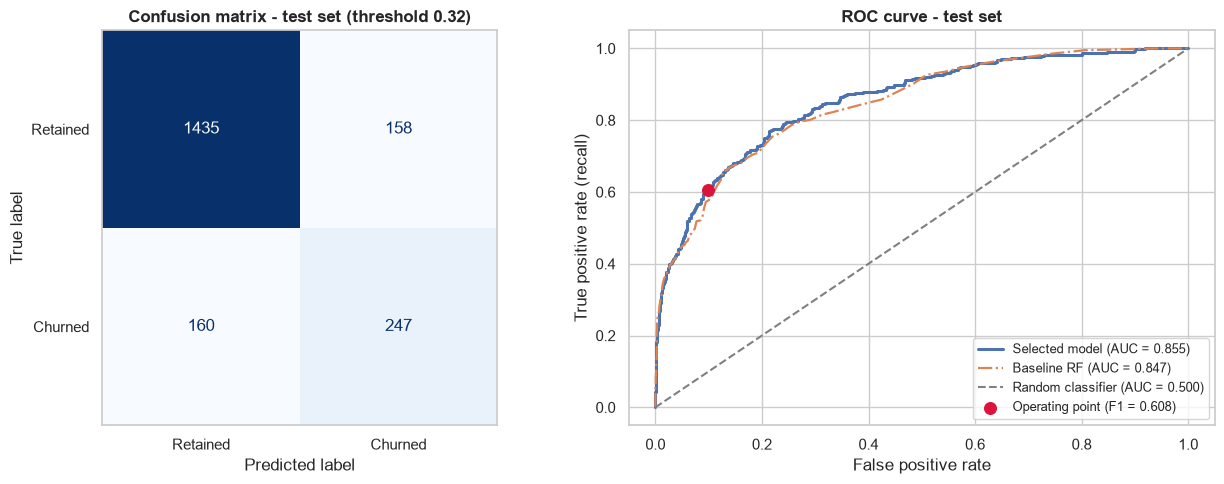

Test set: 2,000 customers, 407 actual churners (20.3%)
True positives : 247  (churners correctly flagged)
False negatives: 160  (churners missed)
False positives: 158  (loyal customers flagged unnecessarily)
Lift: contacting flagged customers is 3.0x more efficient than contacting customers at random


In [70]:
test_pred = (test_proba >= champion_threshold).astype(int)
cm = confusion_matrix(y_test, test_pred)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay(cm, display_labels=["Retained", "Churned"]).plot(ax=axes[0], colorbar=False, cmap="Blues", values_format="d")
axes[0].set_title(f"Confusion matrix - test set (threshold {champion_threshold:.2f})")
axes[0].grid(False)

fpr, tpr, _ = roc_curve(y_test, test_proba)
fpr_b, tpr_b, _ = roc_curve(y_test, reference_model.predict_proba(X_test)[:, 1])
axes[1].plot(fpr, tpr, linewidth=2.2, label=f"Selected model (AUC = {champion_test['AUC-ROC']:.3f})")
axes[1].plot(fpr_b, tpr_b, linewidth=1.6, linestyle="-.", label=f"Baseline RF (AUC = {reference_test['AUC-ROC']:.3f})")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random classifier (AUC = 0.500)")
op_fpr = cm[0, 1] / cm[0].sum(); op_tpr = cm[1, 1] / cm[1].sum()
axes[1].scatter([op_fpr], [op_tpr], color="crimson", zorder=5, s=70, label=f"Operating point (F1 = {champion_test['F1']:.3f})")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate (recall)")
axes[1].set_title("ROC curve - test set"); axes[1].legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
base_rate = y_test.mean()
lift = champion_test["Precision"] / base_rate
print(f"Test set: {len(y_test):,} customers, {int(y_test.sum())} actual churners ({base_rate:.1%})")
print(f"True positives : {tp}  (churners correctly flagged)")
print(f"False negatives: {fn}  (churners missed)")
print(f"False positives: {fp}  (loyal customers flagged unnecessarily)")
print(f"Lift: contacting flagged customers is {lift:.1f}x more efficient than contacting customers at random")

In [71]:
# Written interpretation of the confusion matrix and ROC curve. Figures come from the cell above (cm, tp, fn, fp, lift...).
n_test, n_churn_test = len(y_test), int(y_test.sum())
grid = np.linspace(0, 1, 101)
share_above = float((np.interp(grid, fpr, tpr) >= np.interp(grid, fpr_b, tpr_b)).mean())
sel_precision = champion_test["Precision"]

show_md(f"""**Interpretation (test set: {n_test:,} customers, {n_churn_test} actual churners)**

* The model correctly flags **{tp} churners** and misses **{fn}**; it also raises **{fp} false alarms** among loyal customers.
* Of the customers the model flags, **{sel_precision:.1%}** really do churn, compared with a base rate of {base_rate:.1%}. Targeting flagged customers is therefore **about {lift:.1f} times more efficient than contacting customers at random**.
* On the ROC plot, the selected model's curve is at or above the baseline forest's curve for {share_above:.0%} of the false-positive-rate range. The red dot marks the chosen operating point (false-positive rate {op_fpr:.3f}, true-positive rate {op_tpr:.3f}).
""")


**Interpretation (test set: 2,000 customers, 407 actual churners)**

* The model correctly flags **247 churners** and misses **160**; it also raises **158 false alarms** among loyal customers.
* Of the customers the model flags, **61.0%** really do churn, compared with a base rate of 20.3%. Targeting flagged customers is therefore **about 3.0 times more efficient than contacting customers at random**.
* On the ROC plot, the selected model's curve is at or above the baseline forest's curve for 61% of the false-positive-rate range. The red dot marks the chosen operating point (false-positive rate 0.099, true-positive rate 0.607).


### How certain is the test result?
A single test set of 2,000 customers contains only 407 churners, so any score computed on it carries sampling uncertainty. We quantify it with a **bootstrap** (1,000 resamples of the test set; the model is not retrained).

In [72]:
# Bootstrap the test set to quantify sampling uncertainty of the final metrics
rng = np.random.RandomState(RANDOM_STATE)
y_test_arr = y_test.to_numpy()
pred_arr = (test_proba >= champion_threshold).astype(int)
boot_f1, boot_auc = [], []
for _ in range(1000):
    idx = rng.randint(0, len(y_test_arr), len(y_test_arr))
    boot_f1.append(f1_score(y_test_arr[idx], pred_arr[idx]))
    boot_auc.append(roc_auc_score(y_test_arr[idx], test_proba[idx]))

boot_f1, boot_auc = np.array(boot_f1), np.array(boot_auc)
ci_table = pd.DataFrame({
    "Point estimate": [champion_test["F1"], champion_test["AUC-ROC"]],
    "95% CI - lower": [np.percentile(boot_f1, 2.5), np.percentile(boot_auc, 2.5)],
    "95% CI - upper": [np.percentile(boot_f1, 97.5), np.percentile(boot_auc, 97.5)],
}, index=["F1", "AUC-ROC"])
share_above_target = (boot_f1 >= F1_TARGET).mean()
display(ci_table)
print(f"Share of bootstrap resamples with F1 >= {F1_TARGET}: {share_above_target:.1%}")

,Point estimate,95% CI - lower,95% CI - upper
F1,0.6084,0.5677,0.6465
AUC-ROC,0.8547,0.8307,0.8746


Share of bootstrap resamples with F1 >= 0.59: 81.3%


In [73]:
# Written summary of the bootstrap. Figures come from the table and print above (ci_table, share_above_target).
f1_lo, f1_hi = ci_table.loc["F1", "95% CI - lower"], ci_table.loc["F1", "95% CI - upper"]
auc_lo, auc_hi = ci_table.loc["AUC-ROC", "95% CI - lower"], ci_table.loc["AUC-ROC", "95% CI - upper"]
point_f1 = champion_test["F1"]

if f1_lo >= F1_TARGET:
    margin_line = f"The whole F1 interval lies above the {F1_TARGET} requirement, so the requirement is met with room to spare."
elif point_f1 >= F1_TARGET:
    margin_line = (f"The requirement is met on the test set, but the lower end of the F1 interval ({f1_lo:.3f}) is below {F1_TARGET}: "
                   "the margin is **modest relative to sampling noise**, which is worth stating clearly to stakeholders.")
else:
    margin_line = f"The test F1 ({point_f1:.3f}) is below the {F1_TARGET} requirement, and the interval shows how uncertain that estimate is."

show_md(f"""* The 95% confidence interval for F1 is **{f1_lo:.3f} – {f1_hi:.3f}**, and for AUC-ROC **{auc_lo:.3f} – {auc_hi:.3f}**.
* In {share_above_target:.0%} of the bootstrap resamples the F1 stays at or above the {F1_TARGET} requirement. {margin_line}
""")


* The 95% confidence interval for F1 is **0.568 – 0.646**, and for AUC-ROC **0.831 – 0.875**.
* In 81% of the bootstrap resamples the F1 stays at or above the 0.59 requirement. The requirement is met on the test set, but the lower end of the F1 interval (0.568) is below 0.59: the margin is **modest relative to sampling noise**, which is worth stating clearly to stakeholders.


### What drives the predictions?

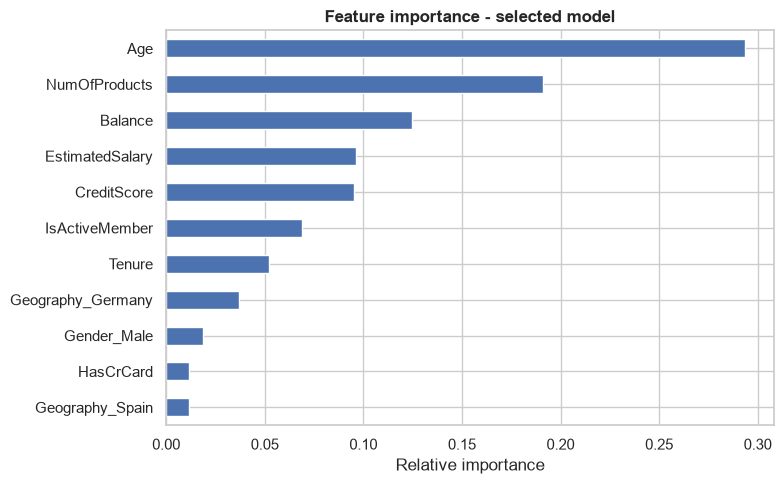

Relative importance of every feature in the selected model:


,Importance
Age,0.294
NumOfProducts,0.191
Balance,0.125
EstimatedSalary,0.096
CreditScore,0.095
IsActiveMember,0.069
Tenure,0.052
Geography_Germany,0.037
Gender_Male,0.019
HasCrCard,0.011


In [74]:
raw_importance = champion.feature_importances_ if hasattr(champion, "feature_importances_") else np.abs(champion.coef_[0])
importances = pd.Series(raw_importance, index=X_train.columns).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
importances.plot(kind="barh", ax=ax, color=sns.color_palette()[0])
ax.set_title("Feature importance - selected model"); ax.set_xlabel("Relative importance")
plt.tight_layout()
plt.show()
top_features = importances.sort_values(ascending=False).head(4)
print("Relative importance of every feature in the selected model:")
display(importances.sort_values(ascending=False).round(3).to_frame("Importance"))


In [75]:
# Written reading of the feature-importance chart. Figures come from the table above (importances).
imp_sorted = importances.sort_values(ascending=False)
n_feat = len(imp_sorted)
rank_of = {feat: pos + 1 for pos, feat in enumerate(imp_sorted.index)}
top3 = imp_sorted.head(3)
top3_names = ", ".join(f"**{feat}** ({val:.2f})" for feat, val in top3.items())
top3_share = top3.sum() / imp_sorted.sum()
eda_overlap = [f for f in top3.index if f in ("Age", "NumOfProducts", "Balance")]
if len(eda_overlap) == 3:
    eda_line = "This agrees with the exploratory analysis, where age, product holdings and balance showed the strongest relationships with churn."
elif eda_overlap:
    eda_line = f"Of these, {', '.join(eda_overlap)} also stood out in the exploratory analysis."
else:
    eda_line = "None of them were among the strongest relationships in the exploratory analysis, which deserves a closer look."

lowest, lowest_val = imp_sorted.index[-1], imp_sorted.iloc[-1]
lowest_line = f"The least important feature is `{lowest}` ({lowest_val:.2f})."
if lowest == "HasCrCard":
    lowest_line += " This is consistent with the EDA, where card ownership had no effect on churn."
act_val, ger_val = imp_sorted["IsActiveMember"], imp_sorted["Geography_Germany"]
act_rank, ger_rank = rank_of["IsActiveMember"], rank_of["Geography_Germany"]
sal_val, cs_val = imp_sorted["EstimatedSalary"], imp_sorted["CreditScore"]
sal_rank, cs_rank = rank_of["EstimatedSalary"], rank_of["CreditScore"]

if hasattr(champion, "feature_importances_"):
    caution = (f"`EstimatedSalary` ({sal_val:.2f}, rank {sal_rank} of {n_feat}) and `CreditScore` ({cs_val:.2f}, rank {cs_rank} of {n_feat}) receive "
               "importance even though the EDA showed almost no difference between churners and retained customers for them. This is a known bias of "
               "impurity-based importance: continuous variables offer many candidate split points, so they receive credit even when their signal is weak. "
               "Binary variables such as `IsActiveMember` and the country indicators tend to be under-rated by the same measure.")
else:
    caution = "The importances shown are absolute coefficient values of a linear model fitted on standardised features; they depend on the scaling of the inputs."

show_md(f"""**Findings**

* The three most important features are {top3_names}. Together they account for about {top3_share:.0%} of the model's total importance. {eda_line}
* `IsActiveMember` has an importance of {act_val:.2f} (rank {act_rank} of {n_feat}) and `Geography_Germany` of {ger_val:.2f} (rank {ger_rank} of {n_feat}). {lowest_line}

**A caution on interpretation.** {caution} This chart should therefore be read as a *rough* guide to the model's behaviour, not as a precise ranking of business drivers. It also does not describe the direction of an effect or prove causality. A permutation-importance or SHAP analysis would be the natural next step.
""")


**Findings**

* The three most important features are **Age** (0.29), **NumOfProducts** (0.19), **Balance** (0.12). Together they account for about 61% of the model's total importance. This agrees with the exploratory analysis, where age, product holdings and balance showed the strongest relationships with churn.
* `IsActiveMember` has an importance of 0.07 (rank 6 of 11) and `Geography_Germany` of 0.04 (rank 8 of 11). The least important feature is `Geography_Spain` (0.01).

**A caution on interpretation.** `EstimatedSalary` (0.10, rank 4 of 11) and `CreditScore` (0.10, rank 5 of 11) receive importance even though the EDA showed almost no difference between churners and retained customers for them. This is a known bias of impurity-based importance: continuous variables offer many candidate split points, so they receive credit even when their signal is weak. Binary variables such as `IsActiveMember` and the country indicators tend to be under-rated by the same measure. This chart should therefore be read as a *rough* guide to the model's behaviour, not as a precise ranking of business drivers. It also does not describe the direction of an effect or prove causality. A permutation-importance or SHAP analysis would be the natural next step.


## 4.2 AUC-ROC compared with F1
The brief asks for AUC-ROC to be measured and compared with F1. The first table shows both metrics for the selected model; the plot shows how they relate across all 12 validated configurations.

In [76]:
comparison = pd.DataFrame({
    "Validation": champion_valid,
    "Test": champion_test,
}).loc[["F1", "AUC-ROC"]]
comparison["Gap (Val - Test)"] = comparison["Validation"] - comparison["Test"]
print("Selected model: F1 and AUC-ROC on the validation and test sets")
display(comparison)

# Do F1 and AUC-ROC rank the three model families in the same way?
# (a) untuned baselines of Section 2 (validation set); (b) tuned models of Section 3 (best configuration per family)
rank_check = pd.DataFrame({
    "Baseline F1": baseline_results.loc[model_order, "F1"],
    "Baseline AUC-ROC": baseline_results.loc[model_order, "AUC-ROC"],
    "Tuned F1": tuned.groupby("Model")["F1 @ best threshold"].max().loc[model_order],
    "Tuned AUC-ROC": tuned.groupby("Model")["AUC-ROC"].max().loc[model_order],
})
print("\nValidation scores per model family (baselines: default hyperparameters, threshold 0.50; tuned: best configuration of the family)")
display(rank_check)
print("Rank of each family under each metric (1 = best)")
display(rank_check.rank(ascending=False, method="min").astype(int))


Selected model: F1 and AUC-ROC on the validation and test sets


,Validation,Test,Gap (Val - Test)
F1,0.6553,0.6084,0.0469
AUC-ROC,0.8745,0.8547,0.0197



Validation scores per model family (baselines: default hyperparameters, threshold 0.50; tuned: best configuration of the family)


,Baseline F1,Baseline AUC-ROC,Tuned F1,Tuned AUC-ROC
Logistic Regression,0.3077,0.7875,0.5393,0.7955
Decision Tree,0.5036,0.6895,0.6266,0.8533
Random Forest,0.6210,0.8624,0.6553,0.8745


Rank of each family under each metric (1 = best)


,Baseline F1,Baseline AUC-ROC,Tuned F1,Tuned AUC-ROC
Logistic Regression,3,2,3,3
Decision Tree,2,3,2,2
Random Forest,1,1,1,1


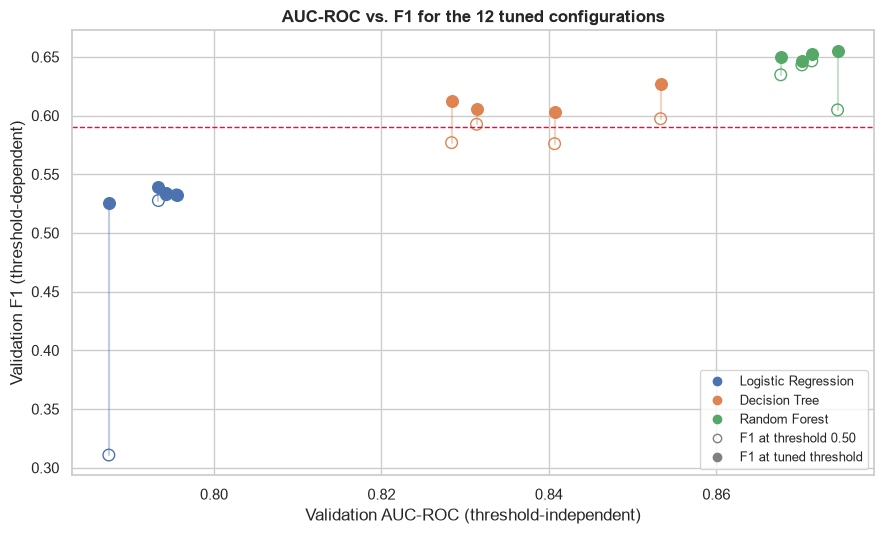

In [77]:
fig, ax = plt.subplots(figsize=(9, 5.5))
palette = dict(zip(model_order, sns.color_palette()[:3]))
for _, row in tuned.iterrows():
    color = palette[row["Model"]]
    ax.plot([row["AUC-ROC"]] * 2, [row["F1 @ 0.50"], row["F1 @ best threshold"]], color=color, alpha=0.35, linewidth=1.5)
    ax.scatter(row["AUC-ROC"], row["F1 @ 0.50"], marker="o", facecolors="none", edgecolors=color, s=70)
    ax.scatter(row["AUC-ROC"], row["F1 @ best threshold"], marker="o", color=color, s=70)
ax.axhline(F1_TARGET, color="crimson", linestyle="--", linewidth=1)
handles = [plt.Line2D([], [], marker="o", linestyle="", color=c, label=m) for m, c in palette.items()]
handles += [plt.Line2D([], [], marker="o", linestyle="", markerfacecolor="none", color="grey", label="F1 at threshold 0.50"),
            plt.Line2D([], [], marker="o", linestyle="", color="grey", label="F1 at tuned threshold")]
ax.legend(handles=handles, loc="lower right", fontsize=9)
ax.set_xlabel("Validation AUC-ROC (threshold-independent)"); ax.set_ylabel("Validation F1 (threshold-dependent)")
ax.set_title("AUC-ROC vs. F1 for the 12 tuned configurations")
plt.tight_layout()
plt.show()

In [78]:
# Written comparison of AUC-ROC and F1 (Section 4.2). Every figure is read from the tables and plots above.
cmp_v_f1, cmp_t_f1 = champion_valid["F1"], champion_test["F1"]
cmp_v_auc, cmp_t_auc = champion_valid["AUC-ROC"], champion_test["AUC-ROC"]
cmp_table = ("| | F1 | AUC-ROC |\n|---|---|---|\n"
             f"| Validation | {cmp_v_f1:.3f} | {cmp_v_auc:.3f} |\n"
             f"| Test | {cmp_t_f1:.3f} | {cmp_t_auc:.3f} |")

auc_drop, f1_drop = cmp_v_auc - cmp_t_auc, cmp_v_f1 - cmp_t_f1
rel_w_f1 = (ci_table.loc["F1", "95% CI - upper"] - ci_table.loc["F1", "95% CI - lower"]) / ci_table.loc["F1", "Point estimate"]
rel_w_auc = (ci_table.loc["AUC-ROC", "95% CI - upper"] - ci_table.loc["AUC-ROC", "95% CI - lower"]) / ci_table.loc["AUC-ROC", "Point estimate"]
if abs(auc_drop) < abs(f1_drop) and rel_w_auc < rel_w_f1:
    stability = (f"**AUC-ROC is more stable.** It changes by {auc_drop:+.3f} from validation to test, versus {f1_drop:+.3f} for F1, and its bootstrap interval "
                 f"is narrower in relative terms ({rel_w_auc:.1%} of the point estimate vs. {rel_w_f1:.1%} for F1). F1 reacts strongly to the threshold and to the small number of positives.")
else:
    stability = (f"**Stability.** AUC-ROC changes by {auc_drop:+.3f} from validation to test, versus {f1_drop:+.3f} for F1; the bootstrap interval is "
                 f"{rel_w_auc:.1%} of the point estimate for AUC-ROC and {rel_w_f1:.1%} for F1.")

threshold_gain = tuned["F1 @ best threshold"] - tuned["F1 @ 0.50"]
hid = tuned.loc[threshold_gain.idxmax()]
max_gain, mean_gain = threshold_gain.max(), threshold_gain.mean()
if max_gain >= 0.05:
    hide_line = (f"In the scatter plot, open circles (F1 at the default 0.50 threshold) lie below the filled circles (F1 at the tuned threshold) by up to {max_gain:.3f}, "
                 f"while the AUC-ROC of each configuration is unchanged. The clearest case is {hid['Model']} with {hid['Strategy'].lower()}: AUC-ROC {hid['AUC-ROC']:.3f}, "
                 f"yet F1 is only {hid['F1 @ 0.50']:.3f} at the default cut-off ({hid['F1 @ best threshold']:.3f} at its tuned threshold). "
                 "AUC-ROC alone would hide that the default threshold is poorly suited to this model.")
else:
    hide_line = f"In this run the gaps between open and filled circles in the scatter plot are small (at most {max_gain:.3f} F1), so the default threshold costs little."

def family_order(col):
    return " > ".join(rank_check[col].sort_values(ascending=False).index)

def disagreements(f1_col, auc_col):
    out = []
    for a, b in itertools.combinations(rank_check.index, 2):
        if (rank_check.loc[a, f1_col] - rank_check.loc[b, f1_col]) * (rank_check.loc[a, auc_col] - rank_check.loc[b, auc_col]) < 0:
            hi, lo = (a, b) if rank_check.loc[a, f1_col] > rank_check.loc[b, f1_col] else (b, a)
            out.append(f"{hi} has a higher F1 than {lo} ({rank_check.loc[hi, f1_col]:.3f} vs {rank_check.loc[lo, f1_col]:.3f}) "
                       f"but a lower AUC-ROC ({rank_check.loc[hi, auc_col]:.3f} vs {rank_check.loc[lo, auc_col]:.3f})")
    return out

tuned_dis = disagreements("Tuned F1", "Tuned AUC-ROC")
base_dis = disagreements("Baseline F1", "Baseline AUC-ROC")
if tuned_dis:
    tuned_line = "For the tuned models the two metrics rank the families differently: " + "; ".join(tuned_dis) + "."
else:
    tuned_line = f"For the tuned models both metrics rank the families the same way ({family_order('Tuned F1')}), and the selected model is at or near the top on both."
if base_dis:
    base_line = "For the untuned baselines of Section 2 the metrics disagree: " + "; ".join(base_dis) + "."
else:
    base_line = f"For the untuned baselines of Section 2 both metrics also agree ({family_order('Baseline F1')})."
if tuned_dis or base_dis:
    rank_conclusion = "The two metrics therefore do not always rank models the same way, which supports the point above that they measure different things: AUC-ROC the quality of the ranking across all thresholds, F1 the quality of the decisions at one threshold."
else:
    rank_conclusion = "In this run the metrics agree on the ordering of the families, but they still measure different things: AUC-ROC the quality of the ranking across all thresholds, F1 the quality of the decisions at one threshold."

show_md(f"""**Comparison**

{cmp_table}

* **They answer different questions.** AUC-ROC ({cmp_t_auc:.3f}) says that if we pick one churner and one loyal customer at random, the model assigns the higher risk to the churner about {cmp_t_auc:.0%} of the time, i.e. its **ranking ability**, regardless of any cut-off. F1 ({cmp_t_f1:.3f}) describes the quality of the **actual yes/no decisions** at one chosen threshold, and requires both good precision *and* good recall for a minority class.
* {stability}
* **AUC-ROC can hide threshold problems.** {hide_line}
* **F1 can look worse than the model really is.** A high AUC-ROC means better decisions are available simply by adjusting the threshold: across the {len(tuned)} configurations, tuning the threshold raises F1 by {mean_gain:.3f} on average (up to {max_gain:.3f}). That is what class weighting and threshold tuning did here.
* **Do the two metrics rank models the same way?** {tuned_line} {base_line} {rank_conclusion} (See the rank tables above.)

**Conclusion:** F1 should be the headline metric for this business problem because it measures the decisions the bank will actually take. AUC-ROC is the right diagnostic for whether the model's scores are informative, and for deciding how much room there is to improve results by re-tuning the threshold, for example if the cost of a retention offer changes.
""")


**Comparison**

| | F1 | AUC-ROC |
|---|---|---|
| Validation | 0.655 | 0.874 |
| Test | 0.608 | 0.855 |

* **They answer different questions.** AUC-ROC (0.855) says that if we pick one churner and one loyal customer at random, the model assigns the higher risk to the churner about 85% of the time, i.e. its **ranking ability**, regardless of any cut-off. F1 (0.608) describes the quality of the **actual yes/no decisions** at one chosen threshold, and requires both good precision *and* good recall for a minority class.
* **AUC-ROC is more stable.** It changes by +0.020 from validation to test, versus +0.047 for F1, and its bootstrap interval is narrower in relative terms (5.1% of the point estimate vs. 13.0% for F1). F1 reacts strongly to the threshold and to the small number of positives.
* **AUC-ROC can hide threshold problems.** In the scatter plot, open circles (F1 at the default 0.50 threshold) lie below the filled circles (F1 at the tuned threshold) by up to 0.215, while the AUC-ROC of each configuration is unchanged. The clearest case is Logistic Regression with no balancing: AUC-ROC 0.787, yet F1 is only 0.311 at the default cut-off (0.526 at its tuned threshold). AUC-ROC alone would hide that the default threshold is poorly suited to this model.
* **F1 can look worse than the model really is.** A high AUC-ROC means better decisions are available simply by adjusting the threshold: across the 12 configurations, tuning the threshold raises F1 by 0.034 on average (up to 0.215). That is what class weighting and threshold tuning did here.
* **Do the two metrics rank models the same way?** For the tuned models both metrics rank the families the same way (Random Forest > Decision Tree > Logistic Regression), and the selected model is at or near the top on both. For the untuned baselines of Section 2 the metrics disagree: Decision Tree has a higher F1 than Logistic Regression (0.504 vs 0.308) but a lower AUC-ROC (0.690 vs 0.788). The two metrics therefore do not always rank models the same way, which supports the point above that they measure different things: AUC-ROC the quality of the ranking across all thresholds, F1 the quality of the decisions at one threshold. (See the rank tables above.)

**Conclusion:** F1 should be the headline metric for this business problem because it measures the decisions the bank will actually take. AUC-ROC is the right diagnostic for whether the model's scores are informative, and for deciding how much room there is to improve results by re-tuning the threshold, for example if the cost of a retention offer changes.


## 4.3 Integrity checks on the pipeline
The cell below verifies, with code, the claims this notebook makes about its own pipeline: the hyperparameter search finished for every model/strategy combination, the selected model really is the leaderboard winner, the three subsets are disjoint and the validation/test sets were not resampled, the confusion matrix and the bootstrap are consistent with the reported metrics, and whether the F1 requirement is met. A row marked `CHECK` would need attention. The written analysis of Sections 3-5 is generated from the same objects that these tables display, so its figures match the displayed results by construction.


In [79]:
checks = []


def add(check, passed, detail=""):
    checks.append({"Check": check, "Result": "OK" if bool(passed) else "CHECK", "Detail": detail})


n_combos = len(param_grids) * len(training_sets)
expected_trials = len(training_sets) * sum(len(expand(g)) for g in param_grids.values())
champ_f1_best = tuned["F1 @ best threshold"].max()

add("Search finished for every model/strategy combination", len(best_models) == n_combos, f"{len(best_models)} of {n_combos}")
add("Every grid configuration was evaluated", len(trials) == expected_trials, f"{len(trials)} of {expected_trials}")
add("Leaderboard ranks every combination", len(tuned) == n_combos, f"{len(tuned)} rows")
add("Selected model has the highest validation F1 of the leaderboard",
    np.isclose(champion_row["F1 @ best threshold"], champ_f1_best),
    f"{champion_row['F1 @ best threshold']:.4f} vs. maximum {champ_f1_best:.4f}")
add("Validation F1 of the selected model is reproduced from its stored predictions",
    np.isclose(champion_valid["F1"], champion_row["F1 @ best threshold"]),
    f"{champion_valid['F1']:.4f} vs. {champion_row['F1 @ best threshold']:.4f}")

index_sets = [set(X_train.index), set(X_valid.index), set(X_test.index)]
disjoint = not (index_sets[0] & index_sets[1] or index_sets[0] & index_sets[2] or index_sets[1] & index_sets[2])
add("Train, validation and test sets are disjoint and cover every customer",
    disjoint and sum(len(s) for s in index_sets) == len(df), f"{[len(s) for s in index_sets]} rows")
natural_gap = max(abs(y_valid.mean() - target.mean()), abs(y_test.mean() - target.mean()))
add("Validation and test sets keep the natural churn rate (no resampling applied to them)", natural_gap < 0.01,
    f"largest deviation {natural_gap:.4f}")
add("Confusion matrix covers the whole test set", int(cm.sum()) == len(y_test), f"{int(cm.sum())} of {len(y_test)} customers")
f1_from_cm = 2 * tp / (2 * tp + fp + fn)
add("Test F1 recomputed from the confusion matrix matches the reported value", np.isclose(f1_from_cm, champion_test["F1"]),
    f"{f1_from_cm:.4f} vs. {champion_test['F1']:.4f}")
add("Bootstrap intervals contain the point estimates",
    all(ci_table.loc[m, "95% CI - lower"] <= ci_table.loc[m, "Point estimate"] <= ci_table.loc[m, "95% CI - upper"] for m in ci_table.index),
    "F1 and AUC-ROC")
add(f"Requirement: test F1 >= {F1_TARGET}", champion_test["F1"] >= F1_TARGET, f"test F1 = {champion_test['F1']:.4f}")

check_table = pd.DataFrame(checks)
n_bad = int((check_table["Result"] == "CHECK").sum())
print(f"{len(check_table) - n_bad} of {len(check_table)} integrity checks passed.")
if n_bad:
    print("Rows marked CHECK need attention.")
with pd.option_context("display.max_colwidth", 80):
    display(check_table)


11 of 11 integrity checks passed.


,Check,Result,Detail
0,Search finished for every model/strategy combination,OK,12 of 12
1,Every grid configuration was evaluated,OK,204 of 204
2,Leaderboard ranks every combination,OK,12 rows
3,Selected model has the highest validation F1 of the leaderboard,OK,0.6553 vs. maximum 0.6553
4,Validation F1 of the selected model is reproduced from its stored predictions,OK,0.6553 vs. 0.6553
5,"Train, validation and test sets are disjoint and cover every customer",OK,"[6000, 2000, 2000] rows"
6,Validation and test sets keep the natural churn rate (no resampling applied ...,OK,largest deviation 0.0003
7,Confusion matrix covers the whole test set,OK,2000 of 2000 customers
8,Test F1 recomputed from the confusion matrix matches the reported value,OK,0.6084 vs. 0.6084
9,Bootstrap intervals contain the point estimates,OK,F1 and AUC-ROC


In [80]:
# Conclusions. Every figure is read from the results computed above, so this section always matches the displayed outputs.
summary_f1, summary_auc = champion_test["F1"], champion_test["AUC-ROC"]
summary_rec, summary_prec = champion_test["Recall"], champion_test["Precision"]
ref_rec_test = reference_test["Recall"]
requirement_mark = "✅" if summary_f1 >= F1_TARGET else "❌ (not met)"
churn_share = target.mean()
best_base = baseline_results.drop(index="Majority-class dummy")["F1"].idxmax()
base_best_recall = baseline_results.loc[best_base, "Recall"]
base_lr_recall = baseline_results.loc["Logistic Regression", "Recall"]
strategy_label = "class weights" if champion_row["Strategy"] == "Class weights" else champion_row["Strategy"].lower()

if len(rf_wins) == len(strategy_order):
    family_line = ("**Random Forest is the best model family**, ahead of the Decision Tree and Logistic Regression under every imbalance strategy. "
                   "This confirms the non-linear, interaction-driven nature of churn seen in the EDA.")
else:
    family_line = f"**Random Forest is the best model family under {len(rf_wins)} of the {len(strategy_order)} imbalance strategies** (see Section 3.3)."

rf_best_strategy = rf_rows["F1 @ best threshold"].idxmax()
rf_worst_strategy = rf_rows["F1 @ best threshold"].idxmin()
recall_verb = "raised" if summary_rec > ref_rec_test else "changed"
strategy_line = (f"**Imbalance strategies (Random Forest, after threshold tuning):** the best is {rf_best_strategy} (validation F1 "
                 f"{rf_rows.loc[rf_best_strategy, 'F1 @ best threshold']:.3f}) and the lowest is {rf_worst_strategy} "
                 f"({rf_rows.loc[rf_worst_strategy, 'F1 @ best threshold']:.3f}); the spread across strategies is {rf_tuned_spread:.3f}. "
                 f"On the test set, the selected model {recall_verb} recall from **{ref_rec_test:.1%} to {summary_rec:.1%}** compared with the untuned baseline forest "
                 f"(precision {reference_test['Precision']:.1%} to {summary_prec:.1%}).")
if n_close >= 1:
    tie_summary = f"{n_close} other candidate(s) are within 0.01 F1 of it, so the choice among the leading variants is a practical one."
else:
    tie_summary = "no other candidate is within 0.01 F1 of it."

ci_f1_lo, ci_f1_hi = ci_table.loc["F1", "95% CI - lower"], ci_table.loc["F1", "95% CI - upper"]
if summary_f1 < F1_TARGET:
    margin_text = f"the requirement of {F1_TARGET} is not met on the test set"
elif ci_f1_lo >= F1_TARGET:
    margin_text = f"the whole interval is above {F1_TARGET}"
else:
    margin_text = f"the lower end is below {F1_TARGET}, so the compliance margin is modest"

if lift > 1:
    lift_line = f"Contacting the flagged customers is about **{lift:.1f}× more efficient** than random outreach."
else:
    lift_line = f"In this run, contacting the flagged customers is not more efficient than random outreach (lift {lift:.1f}×), so the model should not be deployed as is."

show_md(f"""# 5. Conclusions and Recommendations

## Summary of the work
1. **Data quality.** All 14 columns were validated against the data dictionary (16 checks, all passed). The only gap, 909 missing `Tenure` values (9.1%), was random and was imputed with the training median. Identifier columns and `Surname` were removed.
2. **Class imbalance.** Only {churn_share:.1%} of customers churn (imbalance {imbalance_ratio:.2f} : 1). Without any correction, the models under-detected churners: the best baseline ({best_base}) had a recall of {base_best_recall:.1%} on validation data and the baseline Logistic Regression only {base_lr_recall:.1%}.
3. **Imbalance handling.** Class weights, upsampling and downsampling were compared across three model families with hyperparameter search, followed by decision-threshold tuning. All selection used the validation set only.
4. **Final model.** **{champ_model} with {strategy_label}** ({champ_params}), decision threshold {champion_threshold:.2f}. It was selected for having the highest validation F1; {tie_summary}

## Final results on the test set

| Metric | Result | Requirement |
|---|---|---|
| **F1** | **{summary_f1:.3f}** | ≥ {F1_TARGET} {requirement_mark} |
| **AUC-ROC** | **{summary_auc:.3f}** | reported and compared with F1 |
| Recall | {summary_rec:.3f} | — |
| Precision | {summary_prec:.3f} | — |

## Key findings
* {family_line}
* {strategy_line}
* **F1 and AUC-ROC tell complementary stories**: AUC-ROC ({summary_auc:.3f}) shows ranking ability; F1 ({summary_f1:.3f}) shows the quality of the actual decisions at the chosen threshold.
* **Who churns:** customers in **Germany**, **female** customers, **inactive members**, customers aged **40–60**, and customers holding **one, or three or more, products**.

## Business recommendations
1. **Deploy the model as a risk-scoring tool for retention campaigns.** {lift_line}
2. **Set the threshold according to the economics of retention.** The current threshold maximises F1. If an offer is cheap relative to the value of a retained customer, lower the threshold to catch more churners (higher recall); if outreach is expensive, raise it (higher precision).
3. **Design segment-specific retention actions** for the highest-risk profiles: German customers, inactive members, the 40–60 age band, and customers with 3+ products (almost all of whom leave and may point to a product-fit or service issue).
4. **Investigate the product-holding anomaly.** The very high churn among customers with 3–4 products deserves a commercial review.

## Limitations
* The test set includes only {n_churn_test} churners; the F1 confidence interval ({ci_f1_lo:.2f}–{ci_f1_hi:.2f}) shows that {margin_text}.
* Hyperparameters were chosen by F1 at the 0.50 threshold and the threshold was tuned afterwards. A configuration slightly worse at 0.50 could be better at its own optimal threshold; the effect is expected to be small (the top four configurations differ by {top4_spread:.3f} F1) but was not tested.
* The Random Forest grid is compact (two values each for `n_estimators`, `max_depth` and `min_samples_leaf`) to keep the search fast; a wider grid might find a slightly better forest.
* A single train/validation/test split was used. Repeated cross-validation would give more stable estimates.
* The data is a static snapshot, so the model cannot capture changes in behaviour over time, and no cost information (offer cost, customer lifetime value) was available to optimise the threshold financially.
* `Gender` and `Geography` are used as predictors. Before production use, the bank should assess fairness and regulatory implications of using them.

## Suggested next steps
* Evaluate gradient-boosting models (e.g. XGBoost, LightGBM), which often outperform Random Forests on tabular data.
* Replace the single split with stratified cross-validation and calibrate predicted probabilities.
* Add feature engineering (e.g. balance-to-salary ratio, age bands, product-count interactions).
* Optimise the threshold against an explicit cost/benefit model, and monitor the model after deployment for drift.
""")


# 5. Conclusions and Recommendations

## Summary of the work
1. **Data quality.** All 14 columns were validated against the data dictionary (16 checks, all passed). The only gap, 909 missing `Tenure` values (9.1%), was random and was imputed with the training median. Identifier columns and `Surname` were removed.
2. **Class imbalance.** Only 20.4% of customers churn (imbalance 3.91 : 1). Without any correction, the models under-detected churners: the best baseline (Random Forest) had a recall of 52.2% on validation data and the baseline Logistic Regression only 20.6%.
3. **Imbalance handling.** Class weights, upsampling and downsampling were compared across three model families with hyperparameter search, followed by decision-threshold tuning. All selection used the validation set only.
4. **Final model.** **Random Forest with no balancing** ({'n_estimators': 100, 'max_depth': 12, 'min_samples_leaf': 3}), decision threshold 0.32. It was selected for having the highest validation F1; 3 other candidate(s) are within 0.01 F1 of it, so the choice among the leading variants is a practical one.

## Final results on the test set

| Metric | Result | Requirement |
|---|---|---|
| **F1** | **0.608** | ≥ 0.59 ✅ |
| **AUC-ROC** | **0.855** | reported and compared with F1 |
| Recall | 0.607 | — |
| Precision | 0.610 | — |

## Key findings
* **Random Forest is the best model family**, ahead of the Decision Tree and Logistic Regression under every imbalance strategy. This confirms the non-linear, interaction-driven nature of churn seen in the EDA.
* **Imbalance strategies (Random Forest, after threshold tuning):** the best is No balancing (validation F1 0.655) and the lowest is Upsampling (0.647); the spread across strategies is 0.009. On the test set, the selected model raised recall from **44.5% to 60.7%** compared with the untuned baseline forest (precision 70.2% to 61.0%).
* **F1 and AUC-ROC tell complementary stories**: AUC-ROC (0.855) shows ranking ability; F1 (0.608) shows the quality of the actual decisions at the chosen threshold.
* **Who churns:** customers in **Germany**, **female** customers, **inactive members**, customers aged **40–60**, and customers holding **one, or three or more, products**.

## Business recommendations
1. **Deploy the model as a risk-scoring tool for retention campaigns.** Contacting the flagged customers is about **3.0× more efficient** than random outreach.
2. **Set the threshold according to the economics of retention.** The current threshold maximises F1. If an offer is cheap relative to the value of a retained customer, lower the threshold to catch more churners (higher recall); if outreach is expensive, raise it (higher precision).
3. **Design segment-specific retention actions** for the highest-risk profiles: German customers, inactive members, the 40–60 age band, and customers with 3+ products (almost all of whom leave and may point to a product-fit or service issue).
4. **Investigate the product-holding anomaly.** The very high churn among customers with 3–4 products deserves a commercial review.

## Limitations
* The test set includes only 407 churners; the F1 confidence interval (0.57–0.65) shows that the lower end is below 0.59, so the compliance margin is modest.
* Hyperparameters were chosen by F1 at the 0.50 threshold and the threshold was tuned afterwards. A configuration slightly worse at 0.50 could be better at its own optimal threshold; the effect is expected to be small (the top four configurations differ by 0.009 F1) but was not tested.
* The Random Forest grid is compact (two values each for `n_estimators`, `max_depth` and `min_samples_leaf`) to keep the search fast; a wider grid might find a slightly better forest.
* A single train/validation/test split was used. Repeated cross-validation would give more stable estimates.
* The data is a static snapshot, so the model cannot capture changes in behaviour over time, and no cost information (offer cost, customer lifetime value) was available to optimise the threshold financially.
* `Gender` and `Geography` are used as predictors. Before production use, the bank should assess fairness and regulatory implications of using them.

## Suggested next steps
* Evaluate gradient-boosting models (e.g. XGBoost, LightGBM), which often outperform Random Forests on tabular data.
* Replace the single split with stratified cross-validation and calibrate predicted probabilities.
* Add feature engineering (e.g. balance-to-salary ratio, age bands, product-count interactions).
* Optimise the threshold against an explicit cost/benefit model, and monitor the model after deployment for drift.
